# Angular Gini – formal properties of the index (simulation checks)

Code for the property checks of the **Angular Gini** index (M. Schlemmer, *The Angular Gini: Weighting Pairwise Gini Contributions by Proportional Differences*). The Angular Gini weights the contribution of every pair of observations to the Gini coefficient by the angular difference between the two values.

**Definition.** For observations *y*<sub>1</sub>, …, *y*<sub>n</sub> with mean μ > 0:

- pair contribution to the Gini: D<sub>ij</sub> = |y<sub>i</sub> − y<sub>j</sub>| / (n² μ)
- angular difference (in units of 90°): ∠<sub>ij</sub> = |atan2(y<sub>i</sub>, y<sub>j</sub>) − atan2(y<sub>j</sub>, y<sub>i</sub>)| / 90°
- **G<sub>∠</sub> = Σ<sub>i<j</sub> D<sub>ij</sub> · ∠<sub>ij</sub>**

The exponent α (∠<sup>α</sup>) is *not* part of the published index; it is included only to show that the formal properties are not guaranteed for α ≠ 1.

**Contents**
- *Self-tests*: vectorised code versus naive pairwise reference; scale and population invariance; maximum inequality.
- *Arctangent representation* (Proposition 1) and recalculation of **Table 1** of the paper.
- *Bounds*: 0 ≤ G<sub>∠</sub> ≤ Gini ≤ (n−1)/n.
- *Pigou–Dalton principle of transfers*.
- *Diminishing transfers* (Kolm 1976).
- *Weak subgroup decomposability* (exact identity).
- *Gastwirth-type indices*: counterexample and violation rates of the Pigou–Dalton principle (introduction of the paper).
- *Angle-only alternatives*: the Angular Lorenz index (called C in version 1): Pigou–Dalton principle, bounds and population invariance.
- *Negative values*: the numerical examples of Section 4.1, the counterexample of **Table 4**, and the classification of the violating transfers by the signs of the two persons involved.
- *Summary table* (one CSV file with all results) and *figure*.

The notebook is self-contained: it needs only numpy, pandas and matplotlib, and no further files.

Every criterion is checked for non-negative data and for samples that contain a share of negative values, because the paper claims partial validity in that case. The checks are simulations, not proofs: "0 violations" means that no counterexample was found in the given number of random trials.

**Runtime.** About 2–3 minutes with the default settings; `QUICK = True` takes a few seconds.

In [1]:
import math
import time
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# ------------------------------------------------------------------
# Settings
# ------------------------------------------------------------------
QUICK      = False           # True: only 500 trials per table cell (fast look, noisy rates)
TRIALS     = 500 if QUICK else 20_000   # random trials per table cell
SEED       = 2026            # for reproducibility (every experiment derives its own generator)
OUT_DIR    = Path("output")  # CSV file is written here (relative to the notebook folder)
OUT_DIR.mkdir(exist_ok=True)

ALPHAS     = (0.5, 1.0, 2.5) # exponents of the angular term; alpha = 1 is the published index
NEG_SHARES = (0.0, 0.1, 0.2, 0.3, 0.4)  # share of negative values in the samples (0 = non-negative data)

In [2]:
# ------------------------------------------------------------------
# The index
# ------------------------------------------------------------------
@lru_cache(maxsize=None)
def pair_indices(n):
    "Index arrays of all n(n-1)/2 pairs i<j (cached, because n repeats a lot)."
    return np.triu_indices(n, 1)


def angular_difference(a, b):
    '''|atan2(a, b) - atan2(b, a)| in units of 90 degrees.

    For non-negative values it lies in [0, 1]: 0 if a == b (also for a = b = 0, because
    atan2(0, 0) = 0) and 1 if exactly one of the two values is 0. With negative values it can
    reach 2 (e.g. a = -1, b = 1), which is the root of several problems documented below.
    '''
    return np.abs(np.arctan2(a, b) - np.arctan2(b, a)) / (math.pi / 2.0)


def angular_gini(y, alpha=1.0):
    "Angular Gini of the sample y. alpha = 1 is the published index. Needs n >= 2 and a positive mean."
    y = np.asarray(y, dtype=float)
    n, mu = y.size, y.mean()
    if n < 2 or mu <= 0:
        raise ValueError("The Angular Gini needs n >= 2 and a positive mean.")
    i, j = pair_indices(n)
    gini_part  = np.abs(y[i] - y[j]) / (n ** 2 * mu)   # pair contribution to the Gini
    angle_part = angular_difference(y[i], y[j])         # proportional (angular) weight
    return float(np.sum(gini_part * angle_part ** alpha))


def gini(y):
    "Gini coefficient as the sum of the pair contributions D_ij."
    y = np.asarray(y, dtype=float)
    n, mu = y.size, y.mean()
    i, j = pair_indices(n)
    return float(np.sum(np.abs(y[i] - y[j]) / (n ** 2 * mu)))


def draw_distribution(rng, n, neg_share):
    '''Random sorted sample of size n. Positive part: log-normal. A share `neg_share` of the entries
    is replaced by negative values of size up to the sample mean. Retries until the mean is positive
    (needed by the index) and all values are distinct (so that ranks are well defined).'''
    k = int(math.floor(neg_share * n + 0.5))             # number of negative entries
    while True:
        y = rng.lognormal(3.0, 1.0, n)
        if k > 0:
            idx = rng.choice(n, k, replace=False)
            y[idx] = -rng.uniform(0.0, 1.0, k) * y.mean()
        ys = np.sort(y)
        if y.mean() > 0 and np.min(np.diff(ys)) > 1e-9:
            return ys


def row(criterion, alpha, neg_share, n, tests, violations, note=""):
    "One result row (collected in the summary table at the end)."
    return dict(criterion=criterion, alpha=alpha, neg_share=neg_share, n=n,
                tests=tests, violations=violations, note=note)

results = []     # all result rows are appended here

## Self-tests

(1) The vectorised function is compared with a deliberately naive double loop written like the earlier notebooks (angle in degrees, pair term |a−b|/(2·mean), mean over the pairs, division by 90<sup>α</sup>, factor 1 − 1/n). (2) Scale invariance, G<sub>∠</sub>(c·y) = G<sub>∠</sub>(y), and population invariance, G<sub>∠</sub>(y replicated r times) = G<sub>∠</sub>(y). (3) The extreme case in which one person owns everything must give (n−1)/n.

In [3]:
# ------------------------------------------------------------------
# Self-tests
# ------------------------------------------------------------------
def angular_gini_reference(y, alpha=1.0):
    "Naive pairwise implementation in the style of the earlier notebooks (slow, only for checking)."
    y = [float(v) for v in y]
    n = len(y)
    mean = sum(y) / n
    total, c = 0.0, 0
    for a in range(n):
        for b in range(a + 1, n):
            ad = abs(math.degrees(math.atan2(y[a], y[b])) - math.degrees(math.atan2(y[b], y[a])))
            total += (ad ** alpha) * abs(y[a] - y[b]) / (2.0 * mean)
            c += 1
    pre = (total / c) / (90.0 ** alpha)
    return pre - pre / n


rng_st = np.random.default_rng([SEED, 1])
n_st = max(100, TRIALS // 10)

# 1) vectorised code versus naive reference (alpha = 0.5, 1, 2.5; with and without negative values)
dev = 0.0
for _ in range(n_st):
    n = int(rng_st.integers(4, 15))
    y = draw_distribution(rng_st, n, rng_st.choice([0.0, 0.2]))
    for alpha in (0.5, 1.0, 2.5):
        dev = max(dev, abs(angular_gini(y, alpha) - angular_gini_reference(y, alpha)))
print(f"1) vectorised vs. pairwise reference: max |difference| = {dev:.1e} over {n_st} samples")
results.append(row("formula fidelity", "0.5/1/2.5", "0/0.2", "4-14", n_st, int(dev > 1e-12), f"max deviation {dev:.1e}"))

# 2) scale and population invariance
dev_scale = dev_rep = 0.0
for _ in range(TRIALS):
    n = int(rng_st.integers(4, 15))
    y = draw_distribution(rng_st, n, 0.0)
    dev_scale = max(dev_scale, abs(angular_gini(rng_st.uniform(0.01, 100.0) * y) - angular_gini(y)))
    dev_rep   = max(dev_rep,   abs(angular_gini(np.tile(y, int(rng_st.integers(2, 4)))) - angular_gini(y)))
print(f"2) scale invariance: max |difference| = {dev_scale:.1e};  population invariance: {dev_rep:.1e}")
results.append(row("scale invariance", 1.0, 0.0, "4-14", TRIALS, int(dev_scale > 1e-12), f"max deviation {dev_scale:.1e}"))
results.append(row("population invariance", 1.0, 0.0, "4-14", TRIALS, int(dev_rep > 1e-12), f"max deviation {dev_rep:.1e}"))

# 3) maximum inequality: one person owns everything
n = 10
ext = angular_gini(np.r_[np.zeros(n - 1), 1.0])
print(f"3) one owner among n = {n}: Angular Gini = {ext:.6f}, (n-1)/n = {(n - 1) / n:.6f}")
results.append(row("maximum inequality = (n-1)/n", 1.0, 0.0, n, 1, int(abs(ext - (n - 1) / n) > 1e-12), f"Angular Gini = {ext:.6f}"))

1) vectorised vs. pairwise reference: max |difference| = 7.1e-15 over 2000 samples
2) scale invariance: max |difference| = 4.4e-16;  population invariance: 4.4e-16
3) one owner among n = 10: Angular Gini = 0.900000, (n-1)/n = 0.900000


## Arctangent representation (Proposition 1) and Table 1

**Proposition 1.** For non-negative values, ∠<sub>ij</sub> = (4/π)·arctan(|y<sub>i</sub> − y<sub>j</sub>| / (y<sub>i</sub> + y<sub>j</sub>)), with ∠<sub>ij</sub> = 0 for y<sub>i</sub> = y<sub>j</sub> = 0. The proposition is proved in the paper; here the atan2 definition is compared numerically with the arctangent formula (including zeros and the pair (0, 0)), and the range 0 ≤ ∠ ≤ 1 and the value ∠ = 1 for exactly one zero are checked.

The second part recalculates the numbers of **Table 1** (incomes 4, 8, 12, 36, 40) and the value of Figure 1 (y<sub>i</sub> = 2·y<sub>j</sub>). `compare_to_paper` counts the published numbers that differ from the recalculated ones at the printed precision.

In [4]:
# ------------------------------------------------------------------
# Proposition 1 (arctangent representation) and Table 1
# ------------------------------------------------------------------
def compare_to_paper(computed, published, decimals):
    "Number of published values that differ from the recalculated ones at the printed precision."
    return sum(abs(round(float(c), d) - p) > 1e-12 for c, p, d in zip(computed, published, decimals))


def angular_difference_arctan(a, b):
    "(4/pi) * arctan(|a-b| / (a+b)) for non-negative a, b; 0 if a = b = 0 (Proposition 1, Eq. 3)."
    a, b = np.asarray(a, float), np.asarray(b, float)
    s = a + b
    g = np.divide(np.abs(a - b), s, out=np.zeros_like(s), where=s > 0)
    return 4.0 / math.pi * np.arctan(g)


rng_p = np.random.default_rng([SEED, 6])
a = rng_p.lognormal(3.0, 1.5, TRIALS)
b = rng_p.lognormal(3.0, 1.5, TRIALS)
a[rng_p.random(TRIALS) < 0.1] = 0.0                       # about 10 % zeros, so that (0, y) and (0, 0) occur
b[rng_p.random(TRIALS) < 0.1] = 0.0
ang = angular_difference(a, b)
dev_p = float(np.max(np.abs(ang - angular_difference_arctan(a, b))))
one_zero = (a == 0) != (b == 0)
ok_range = bool(np.all((ang >= 0) & (ang <= 1 + 1e-12)))
ok_one_zero = bool(np.all(np.abs(ang[one_zero] - 1.0) < 1e-12))
ok_equal = bool(np.all(ang[a == b] < 1e-12))
print(f"Proposition 1: max |atan2 version - arctan version| = {dev_p:.1e} over {TRIALS} pairs "
      f"({int(np.sum(a == 0) + np.sum(b == 0))} zeros, {int(np.sum((a == 0) & (b == 0)))} pairs (0, 0))")
print(f"  range [0, 1]: {ok_range};  exactly one zero -> 1: {ok_one_zero};  equal values -> 0: {ok_equal}")
results.append(row("arctangent representation (Proposition 1)", 1.0, 0.0, "pairs", TRIALS,
                   int(dev_p > 1e-12 or not (ok_range and ok_one_zero and ok_equal)),
                   f"max deviation {dev_p:.1e}"))

# Figure 1: y_i = 2 y_j
print(f"\nFigure 1 (y_i = 2 y_j): angular difference = {float(angular_difference(2.0, 1.0)):.4f}"
      f" = (4/pi) arctan(1/3) = {4 / math.pi * math.atan(1 / 3):.4f}")

# Table 1: incomes 4, 8, 12, 36, 40
y_t1 = np.array([4, 8, 12, 36, 40], float)
n1, mu1 = y_t1.size, y_t1.mean()
pairs_t1 = [(4, 8), (8, 12), (36, 40)]
tab1 = []
for p, q in pairs_t1:
    D = abs(p - q) / (n1 ** 2 * mu1)
    ang_pq = float(angular_difference(p, q))
    tab1.append({"pair": f"({p}, {q})", "D_ij * 1e3": D * 1e3, "angle": ang_pq, "D_ij * angle * 1e3": D * ang_pq * 1e3})
tab1 = pd.DataFrame(tab1)
display(tab1.round(3))
print(f"whole series: n = {n1}, mean = {mu1:g}, Gini = {gini(y_t1):.3f}, Angular Gini = {angular_gini(y_t1):.3f}")

computed  = list(tab1["D_ij * 1e3"]) + list(tab1["angle"]) + list(tab1["D_ij * angle * 1e3"]) + [gini(y_t1), angular_gini(y_t1)]
published = [8.0, 8.0, 8.0,  0.410, 0.251, 0.067,  3.28, 2.01, 0.54,  0.400, 0.285]
decimals  = [1, 1, 1,  3, 3, 3,  2, 2, 2,  3, 3]
bad = compare_to_paper(computed, published, decimals)
print(f"Table 1 of the paper: {len(published)} numbers compared, {bad} differ")
results.append(row("Table 1 reproduced", 1.0, 0.0, 5, len(published), bad, "incomes 4, 8, 12, 36, 40"))


Proposition 1: max |atan2 version - arctan version| = 3.3e-16 over 20000 pairs (3986 zeros, 180 pairs (0, 0))
  range [0, 1]: True;  exactly one zero -> 1: True;  equal values -> 0: True

Figure 1 (y_i = 2 y_j): angular difference = 0.4097 = (4/pi) arctan(1/3) = 0.4097


,pair,D_ij * 1e3,angle,D_ij * angle * 1e3
0,"(4, 8)",8.0,0.410,3.277
1,"(8, 12)",8.0,0.251,2.011
2,"(36, 40)",8.0,0.067,0.536


whole series: n = 5, mean = 20, Gini = 0.400, Angular Gini = 0.285
Table 1 of the paper: 11 numbers compared, 0 differ


## Bounds

For non-negative data the Angular Gini must satisfy 0 ≤ G<sub>∠</sub> ≤ Gini ≤ (n−1)/n, because ∠ ≤ 1. With negative values the angular difference can reach 2 and the mean can approach 0, so the bound may be exceeded. `violations` counts the samples with G<sub>∠</sub> > (n−1)/n (or G<sub>∠</sub> > Gini).

In [5]:
# ------------------------------------------------------------------
# Bounds: 0 <= G_angle <= Gini <= (n-1)/n
# ------------------------------------------------------------------
rng_b = np.random.default_rng([SEED, 2])
rows_b = []
for s in NEG_SHARES:
    viol, largest = 0, 0.0
    for _ in range(TRIALS):
        n = int(rng_b.integers(5, 21))
        y = draw_distribution(rng_b, n, s)
        v = angular_gini(y)
        largest = max(largest, v)
        if v > (n - 1) / n + 1e-12 or v > gini(y) + 1e-12 or v < -1e-12:
            viol += 1
    rows_b.append(row("bounds 0<=G_angle<=Gini<=(n-1)/n", 1.0, s, "5-20", TRIALS, viol, f"largest Angular Gini = {largest:.3g}"))
results += rows_b
df_b = pd.DataFrame(rows_b)
df_b["violation_%"] = (100 * df_b["violations"] / df_b["tests"]).round(1)
display(df_b[["neg_share", "tests", "violations", "violation_%", "note"]])

,neg_share,tests,violations,violation_%,note
0,0.0,20000,0,0.0,largest Angular Gini = 0.825
1,0.1,20000,8675,43.4,largest Angular Gini = 9.18
2,0.2,20000,16681,83.4,largest Angular Gini = 18.6
3,0.3,20000,19527,97.6,largest Angular Gini = 5.8e+03
4,0.4,20000,19867,99.3,largest Angular Gini = 9.81e+03


## Pigou–Dalton principle of transfers

A progressive transfer (from a richer to a poorer person, without changing the rank order) must lower the index. In every trial a sorted sample is drawn, an amount δ is moved from a richer person *b* to a poorer person *a*, with δ below half of their gap and below the gaps to the neighbours, so that no ranks change. A *violation* is a transfer after which the index stays equal or increases.

In [6]:
# ------------------------------------------------------------------
# Pigou-Dalton principle of transfers
# ------------------------------------------------------------------
def pigou_dalton(rng, alpha, neg_share, trials):
    viol = 0
    for _ in range(trials):
        n = int(rng.integers(5, 21))
        y = draw_distribution(rng, n, neg_share)          # sorted, distinct values
        a = int(rng.integers(0, n - 1))                   # poorer person (index in the sorted sample)
        b = int(rng.integers(a + 1, n))                   # richer person
        room = [(y[b] - y[a]) / 2.0]                      # donor and recipient must not cross
        if a + 1 != b:
            room.append(y[a + 1] - y[a])                  # recipient must not pass the next value
            room.append(y[b] - y[b - 1])                  # donor must not pass the previous value
        delta = min(room) * rng.uniform(0.05, 0.95)
        z = y.copy()
        z[a] += delta
        z[b] -= delta
        if angular_gini(z, alpha) >= angular_gini(y, alpha) - 1e-13:
            viol += 1
    return viol


rng_pd = np.random.default_rng([SEED, 3])
t0 = time.time()
rows_pd = [row("Pigou-Dalton", alpha, s, "5-20", TRIALS, pigou_dalton(rng_pd, alpha, s, TRIALS))
           for alpha in ALPHAS for s in NEG_SHARES]
results += rows_pd
print(f"Pigou-Dalton: {len(rows_pd)} cells in {time.time() - t0:.0f} s")

df_pd = pd.DataFrame(rows_pd)
df_pd["violation_%"] = 100 * df_pd["violations"] / df_pd["tests"]
display(df_pd.pivot(index="alpha", columns="neg_share", values="violation_%").round(2)
        .rename_axis(index="alpha", columns="share of negative values"))

Pigou-Dalton: 15 cells in 31 s


share of negative values,0.0,0.1,0.2,0.3,0.4
alpha,,,,,
0.5,0.0,0.03,0.24,0.77,1.42
1.0,0.0,0.04,0.44,1.38,2.14
2.5,0.0,0.15,0.91,2.60,3.74


## Diminishing transfers (Kolm 1976)

Two pairs with the **same absolute difference** *d* are placed in the sample: a lower pair (lo, lo+d) and an upper pair (hi, hi+d) with hi > lo + d, plus *n*−4 further values. In two separate experiments the same transfer δ is moved from the richer to the poorer member of the lower pair and of the upper pair. The principle demands that the reduction of the index is **larger for the lower pair**. A *violation* is `reduction_lower <= reduction_upper`.

- `marginal`: δ is tiny (10<sup>−5</sup>·d); this compares the derivatives and avoids rank changes.
- `finite`: δ is a quarter of the smallest gap in the sample (no rank changes).
- In the non-negative case the lower pair starts at exactly 0 in 20 % of the trials (zero incomes are the most demanding edge case). With negative values the lower pair starts at a negative value.

**Added with the proofs:** the random designs below use n ≤ 20 and cannot reach the configurations in which the principle fails for large populations. The principle is proved under a dispersion bound, and a counterexample for large n is documented in the section "Analytic results" after this cell.

In [7]:
# ------------------------------------------------------------------
# Diminishing transfers (Kolm)
# ------------------------------------------------------------------
KOLM_SHARES = (0.0, 0.2, 0.4)   # shares of negative values for this test
KOLM_SIZES  = (5, 10, 20)       # sample sizes

def kolm(rng, alpha, neg_share, n, trials, mode="marginal"):
    n_neg = int(math.floor(neg_share * n + 0.5))
    viol = done = 0
    while done < trials:
        d = rng.uniform(1.0, 80.0)                        # common absolute difference of the two pairs
        # remaining n-4 values: log-normal with randomly varied location/spread, so that the pairs
        # sit at very different places in the distribution
        rest = rng.lognormal(rng.uniform(1.0, 4.5), rng.uniform(0.3, 1.2), n - 4)
        if n_neg == 0:
            lo = 0.0 if rng.random() < 0.2 else rng.uniform(0.0, 80.0)
        else:
            lo = -rng.uniform(0.0, 40.0)
        hi = lo + d + rng.uniform(1.0, 200.0)
        if n_neg > 1:                                     # remaining negatives sit in `rest`
            k = min(n_neg - 1, rest.size)
            rest[rng.choice(rest.size, k, replace=False)] = -rng.uniform(0.0, 40.0, k)
        y = np.r_[rest, lo, lo + d, hi, hi + d]           # last four entries: lower pair, upper pair
        if y.mean() <= 0:
            continue
        gaps = np.diff(np.sort(y))
        gaps = gaps[gaps > 1e-9]
        delta = 1e-5 * d if mode == "marginal" else min(d / 4.0, gaps.min() / 4.0)
        base = angular_gini(y, alpha)

        def reduction(pos):                               # pos = position of the poorer member of the pair
            z = y.copy()
            z[pos] += delta                               # poorer member gains
            z[pos + 1] -= delta                           # richer member loses
            return base - angular_gini(z, alpha)

        if reduction(n - 4) <= reduction(n - 2):          # lower pair must reduce MORE than upper pair
            viol += 1
        done += 1
    return viol


rng_k = np.random.default_rng([SEED, 4])
t0 = time.time()
rows_k = [row("diminishing transfers (marginal)", alpha, s, n, TRIALS, kolm(rng_k, alpha, s, n, TRIALS))
          for alpha in ALPHAS for s in KOLM_SHARES for n in KOLM_SIZES]
# finite transfers: only the published index (alpha = 1), fewer trials
trials_fin = max(200, TRIALS // 5)
rows_k += [row("diminishing transfers (finite)", 1.0, s, n, trials_fin,
               kolm(rng_k, 1.0, s, n, trials_fin, mode="finite"))
           for s in (0.0, 0.2) for n in (5, 10)]
results += rows_k
print(f"Kolm: {len(rows_k)} cells in {time.time() - t0:.0f} s")

df_k = pd.DataFrame(rows_k)
df_k["violation_%"] = 100 * df_k["violations"] / df_k["tests"]
m = df_k[df_k["criterion"].str.contains("marginal")]
display(m.pivot_table(index=["alpha", "neg_share"], columns="n", values="violations", aggfunc="sum")
        .rename_axis(columns="n").astype(int).assign(tests_per_cell=TRIALS))
display(df_k[df_k["criterion"].str.contains("finite")][["alpha", "neg_share", "n", "tests", "violations"]])

Kolm: 31 cells in 76 s


n                  5   10    20  tests_per_cell
alpha neg_share                                
0.5   0.0          3   24    37           20000
      0.2        388  831  1070           20000
      0.4          0  173   328           20000
1.0   0.0          0    0     0           20000
      0.2        278  578   704           20000
      0.4          1  137   311           20000
2.5   0.0          0    1     1           20000
      0.2         97  232   321           20000
      0.4         76  314   382           20000

,alpha,neg_share,n,tests,violations
27,1.0,0.0,5,4000,0
28,1.0,0.0,10,4000,0
29,1.0,0.2,5,4000,41
30,1.0,0.2,10,4000,168


## Analytic results: Pigou–Dalton, diminishing transfers, and a counterexample

The manuscript now *proves* the two transfer principles for non-negative data (Section 3). This section checks the ingredients of the proofs numerically and documents the counterexample. Notation: h(x, y) = |y−x|·(4/π)·arctan(|y−x|/(x+y)) is the pair function, so that G<sub>∠</sub> = Σ<sub>i<j</sub> h(y<sub>i</sub>, y<sub>j</sub>) / (n²μ).

- **Lemma 1:** h is convex on the closed quadrant [0, ∞)². Together with symmetry this gives Proposition 5 (Pigou–Dalton), without any restriction on the rank order and for every transfer that does not overshoot the poorer person (δ < y<sub>b</sub> − y<sub>a</sub>); the proof in the manuscript uses strict convexity along the segment between y and the sample with a and b swapped.
- **Lemma 2:** ∂²h/∂t² = κ(x, t) = (8/π)·x²(x+t)/(x²+t²)², and ∂κ/∂t < 0 exactly if x < (2+√7)·t. The marginal reduction of the index by a transfer from b to a equals S′(y<sub>b</sub>) − S′(y<sub>a</sub>) = ∫ Λ(t) dt over [y<sub>a</sub>, y<sub>b</sub>] with S(t) = Σ<sub>k</sub> h(y<sub>k</sub>, t) and Λ = S″.
- **Proposition 6:** if no income exceeds (2+√7)·y<sub>a</sub> ≈ 4.65·y<sub>a</sub>, then Λ is strictly decreasing on [y<sub>a</sub>, ∞), and the marginal reduction is larger for the lower of two pairs with the same gap. (Checked here with up to 3000 persons per income.)
- **Example 1:** the dispersion condition cannot be dropped. Many persons far above both pairs make Λ *increase* over the relevant range, because κ(x, t) rises in t for t < x/(2+√7). With the incomes 1, 6, 18, 23 and 1000 incomes equal to 93 the transfer in the upper pair (18, 23) reduces the index by more than the same transfer in the lower pair (1, 6). The random designs above (n ≤ 20) cannot reach such configurations, which is why they found no violation.

The high-precision confirmation at the end of the cell needs `mpmath`; it is skipped if the package is not installed.

**Terminology.** The principle checked here is Kolm's (1976) *principle of diminishing transfers* (Unequal Inequalities II, Section VII). Chateauneuf, Gajdos & Wilthien (2002, "CGW") use the label *strong diminishing transfer* for a different, weaker principle that combines diminishing transfers with the *dual* principle of Mehran (1976) and Kakwani (1980): the two transfers must have the same rank gap and the same income gap (their Definition 4); Definition 3 (dual diminishing transfer) requires only the same rank gap. The last part of the cell below checks both for the Angular Gini: Example 1 also violates Definition 4, the random designs with n ≤ 30 do not, and Definition 3 is violated often, because the Angular Gini is not rank-based (the Gini coefficient satisfies Definition 3 in the weak form, with equal effects for equal rank gaps).

In [8]:
# ------------------------------------------------------------------
# Analytic results: checks of Lemma 1-2 and Propositions 5-6 (Pigou-Dalton; diminishing transfers)
# and the counterexample to the principle without a dispersion condition
# ------------------------------------------------------------------
K4       = 4.0 / math.pi
RHO_STAR = 2.0 + math.sqrt(7.0)          # = 4.646...: the dispersion bound of Proposition 6


def pair_h(x, y):
    "Pair function h(x,y) = |y-x| (4/pi) arctan(|y-x|/(x+y)), h(0,0) = 0.  AG = sum_{i<j} h(y_i,y_j) / (n^2 mu)."
    x, y = np.asarray(x, float), np.asarray(y, float)
    s = x + y
    r = np.divide(np.abs(y - x), s, out=np.zeros_like(s), where=s > 0)
    return K4 * np.abs(y - x) * np.arctan(r)


def kappa(x, t):
    "Second derivative of h(x, t) with respect to t:  (8/pi) x^2 (x+t) / (x^2+t^2)^2   (Lemma 2)."
    x, t = np.asarray(x, float), np.asarray(t, float)
    return 8.0 / math.pi * x**2 * (x + t) / (x**2 + t**2) ** 2


def dkappa(x, t):
    "Third derivative:  (8/pi) x^2 (x^2 - 4xt - 3t^2) / (x^2+t^2)^3; negative iff x < RHO_STAR * t."
    x, t = np.asarray(x, float), np.asarray(t, float)
    return 8.0 / math.pi * x**2 * (x**2 - 4 * x * t - 3 * t**2) / (x**2 + t**2) ** 3


def h_t(x, t):
    "First derivative of h(x, t) with respect to t (x >= 0, t > 0)."
    x, t = np.asarray(x, float), np.asarray(t, float)
    s, d = x + t, t - x
    r = d / s
    return K4 * np.arctan(r) + K4 * d / (1 + r * r) * 2 * x / s**2


def S_prime(t, vals, mult):
    "S'(t) for S(t) = sum_k mult_k h(vals_k, t): the marginal effect of the whole sample on an income t."
    return float(np.sum(np.asarray(mult, float) * h_t(np.asarray(vals, float), t)))


def AG_grouped(vals, mult):
    "Angular Gini of a sample given as distinct values with multiplicities (for very large n)."
    vals, mult = np.asarray(vals, float), np.asarray(mult, float)
    n, mu = mult.sum(), float(np.sum(vals * mult)) / mult.sum()
    X, Y = np.meshgrid(vals, vals, indexing="ij")
    return float(0.5 * np.sum(pair_h(X, Y) * np.outer(mult, mult)) / (n * n * mu))


rng_a = np.random.default_rng([SEED, 20])

# (1) Lemma 1: h is convex on the closed quadrant (random segments, 10 % of the coordinates on the axes)
viol = 0
for _ in range(TRIALS * 10):
    p = rng_a.exponential(1.0, 2) * (rng_a.random(2) > 0.1)
    q = rng_a.exponential(1.0, 2) * (rng_a.random(2) > 0.1)
    lam = rng_a.random()
    m = lam * p + (1 - lam) * q
    viol += int(pair_h(m[0], m[1]) > lam * pair_h(p[0], p[1]) + (1 - lam) * pair_h(q[0], q[1]) + 1e-12)
print(f"Lemma 1 (convexity of the pair function): {viol} violations in {TRIALS * 10} random segments")
results.append(row("Lemma 1: pair function convex", 1.0, 0.0, "pairs", TRIALS * 10, viol))

# (2) Lemma 2: h_t, kappa and dkappa against central differences of the previous derivative; sign rule of dkappa
dev_ht = dev_k = dev_dk = 0.0
sign_bad = 0
for _ in range(TRIALS):
    t = rng_a.uniform(0.05, 20.0)
    x = t * 10 ** rng_a.uniform(-2, 2)
    e = 1e-4 * t
    num_ht = (pair_h(x, t + e) - pair_h(x, t - e)) / (2 * e)
    num_k = (h_t(x, t + e) - h_t(x, t - e)) / (2 * e)
    num_dk = (kappa(x, t + e) - kappa(x, t - e)) / (2 * e)
    dev_ht = max(dev_ht, abs(num_ht - h_t(x, t)) / abs(h_t(x, t)))
    dev_k = max(dev_k, abs(num_k - kappa(x, t)) / kappa(x, t))
    dev_dk = max(dev_dk, abs(num_dk - dkappa(x, t)) / max(abs(dkappa(x, t)), 1e-12))
    sign_bad += int((dkappa(x, t) < 0) != (x < RHO_STAR * t))
dev_all = max(dev_ht, dev_k, dev_dk)
print(f"Lemma 2: max relative deviation of h_t {dev_ht:.1e}, of kappa {dev_k:.1e}, of dkappa {dev_dk:.1e}; sign rule violated {sign_bad} times")
results.append(row("Lemma 2: kernel formula and sign rule", 1.0, 0.0, "pairs", TRIALS, int(dev_all > 1e-5 or sign_bad > 0),
                   f"max rel. deviation {dev_all:.1e}"))

# (3) Lemma 2: marginal reduction of a transfer equals S'(y_b) - S'(y_a)
dev_m = 0.0
for _ in range(TRIALS // 4):
    n = int(rng_a.integers(4, 13))
    y = np.sort(rng_a.lognormal(2.0, 1.0, n))
    a = int(rng_a.integers(0, n - 1))
    b = int(rng_a.integers(a + 1, n))
    e = 1e-6 * y[a]

    def Gam(z):
        i, j = pair_indices(n)
        return float(np.sum(pair_h(z[i], z[j])))
    zp, zm = y.copy(), y.copy()
    zp[a] += e; zp[b] -= e
    zm[a] -= e; zm[b] += e
    num = (Gam(zm) - Gam(zp)) / (2 * e)            # reduction rate of the transfer b -> a
    ana = S_prime(y[b], y, np.ones(n)) - S_prime(y[a], y, np.ones(n))
    dev_m = max(dev_m, abs(num - ana) / abs(ana))
print(f"Lemma 2: marginal reduction versus S'(y_b) - S'(y_a): max relative deviation {dev_m:.1e}")
results.append(row("Lemma 2: marginal reduction = S'(b) - S'(a)", 1.0, 0.0, "4-12", TRIALS // 4, int(dev_m > 1e-5), f"max rel. deviation {dev_m:.1e}"))

# (4) Proposition 5 (Pigou-Dalton) in a design WITHOUT rank restriction: any delta in (0, y_b - y_a), up to 30 % zeros
viol, worst = 0, np.inf
for _ in range(TRIALS):
    n = int(rng_a.integers(3, 21))
    y = rng_a.lognormal(3.0, rng_a.uniform(0.3, 2.0), n)
    y[rng_a.random(n) < rng_a.choice([0.0, 0.15, 0.3])] = 0.0
    if y.mean() <= 0 or np.ptp(y) == 0:
        continue
    a, b = rng_a.choice(n, 2, replace=False)
    if y[a] > y[b]:
        a, b = b, a
    if y[a] == y[b]:
        continue
    delta = rng_a.uniform(0.05, 0.95) * (y[b] - y[a])
    z = y.copy(); z[a] += delta; z[b] -= delta
    fall = angular_gini(y) - angular_gini(z)
    worst = min(worst, fall)
    viol += int(fall <= 1e-13)
print(f"Proposition 5 (Pigou-Dalton, no rank restriction, delta up to the full gap, zeros allowed): {viol} violations in {TRIALS}; smallest decrease {worst:.1e}")
results.append(row("Proposition 5: Pigou-Dalton, no rank restriction", 1.0, 0.0, "3-20", TRIALS, viol, f"smallest decrease {worst:.1e}"))

# (5) Proposition 6: under y_max <= RHO_STAR * y_a the lower pair always has the larger marginal reduction
viol, done = 0, 0
smallest_margin = np.inf
while done < TRIALS:
    a = rng_a.uniform(0.1, 10.0)
    top = RHO_STAR * a
    D = rng_a.uniform(0.01, 0.3) * top
    gap = rng_a.uniform(0.001, 0.5) * top
    b, c = a + D, a + D + gap
    d = c + D
    if d > top:
        continue
    m_oth = int(rng_a.integers(0, 5))
    oth = rng_a.uniform(0.0, top, m_oth)
    if m_oth and rng_a.random() < 0.3:
        oth[0] = 0.0                                # zero incomes among the others
    mult = np.r_[1, 1, 1, 1, rng_a.integers(1, 3000, m_oth)]
    vals = np.r_[a, b, c, d, oth]
    R1 = S_prime(b, vals, mult) - S_prime(a, vals, mult)
    R2 = S_prime(d, vals, mult) - S_prime(c, vals, mult)
    smallest_margin = min(smallest_margin, (R1 - R2) / R1)
    viol += int(R1 <= R2)
    done += 1
print(f"Proposition 6 (y_max <= (2+sqrt7) y_a, marginal transfers, up to 3000 persons per income): {viol} violations in {TRIALS}; "
      f"smallest relative margin (R_lower - R_upper)/R_lower = {smallest_margin:.1e}")
results.append(row("Proposition 6: diminishing transfers under y_max <= (2+sqrt7) y_a", 1.0, 0.0, "6-20 values", TRIALS, viol,
                   f"smallest relative margin {smallest_margin:.1e}"))

# (6) Example 1: without a dispersion condition the principle fails in large populations
vals0 = [1.0, 6.0, 18.0, 23.0, 93.0]
print("\nExample 1: incomes 1, 6, 18, 23 and m incomes equal to 93 (pairs (1,6) and (18,23), common gap 5)")
rows_ex = []
for m_rich in (300, 500, 1000, 3000):
    mult0 = [1, 1, 1, 1, m_rich]
    base = AG_grouped(vals0, mult0)
    out = {"n": m_rich + 4}
    for delta in (0.05,):
        lo = AG_grouped([1.0 + delta, 6.0 - delta, 18.0, 23.0, 93.0], mult0)
        up = AG_grouped([1.0, 6.0, 18.0 + delta, 23.0 - delta, 93.0], mult0)
        out["red_lower(0.05)"], out["red_upper(0.05)"] = base - lo, base - up
    out["marginal_lower"] = S_prime(6.0, vals0, mult0) - S_prime(1.0, vals0, mult0)
    out["marginal_upper"] = S_prime(23.0, vals0, mult0) - S_prime(18.0, vals0, mult0)
    out["violation"] = bool(out["marginal_upper"] >= out["marginal_lower"])
    rows_ex.append(out)
display(pd.DataFrame(rows_ex).style.format({"red_lower(0.05)": "{:.4e}", "red_upper(0.05)": "{:.4e}",
                                          "marginal_lower": "{:.6f}", "marginal_upper": "{:.6f}"}))
ex1000 = [r for r in rows_ex if r["n"] == 1004][0]
print(f"n = 1004: reduction in the lower pair {ex1000['red_lower(0.05)']:.4e}, in the upper pair {ex1000['red_upper(0.05)']:.4e} "
      f"(delta = 0.05); the principle is violated: {ex1000['red_upper(0.05)'] > ex1000['red_lower(0.05)']}")
def _viol(m_rich):
    mu_ = [1, 1, 1, 1, m_rich]
    return (S_prime(23.0, vals0, mu_) - S_prime(18.0, vals0, mu_)) >= (S_prime(6.0, vals0, mu_) - S_prime(1.0, vals0, mu_))
smallest = next(m for m in range(1, 5001) if _viol(m))
always = all(_viol(m) for m in range(smallest, 5001))
print(f"for these incomes the marginal reduction in the upper pair is the larger one from m = {smallest} (n = {smallest + 4}) on "
      f"(checked up to m = 5000; no exception: {always})")
results.append(row("Example 1: diminishing transfers fails for n = 1004", 1.0, 0.0, 1004, 1,
                   int(not (ex1000["red_upper(0.05)"] > ex1000["red_lower(0.05)"])),
                   f"red_lower {ex1000['red_lower(0.05)']:.4e} < red_upper {ex1000['red_upper(0.05)']:.4e}; first violating n = {smallest + 4}"))

try:                                                   # optional high-precision confirmation (only if mpmath is installed)
    from mpmath import mp, mpf, atan as _atan, pi as _pi
    mp.dps = 60
    def _h(x, y):
        x, y = mpf(x), mpf(y); s = x + y
        return mpf(0) if s == 0 else 4 / _pi * (y - x) * _atan((y - x) / s)
    def _ag(v, mu_):
        n_ = sum(mu_); mean = sum(mpf(a) * k for a, k in zip(v, mu_)) / n_
        return sum(_h(v[i], v[j]) * mu_[i] * mu_[j] for i in range(len(v)) for j in range(i + 1, len(v))) / (n_ * n_ * mean)
    for dl in ("1e-6", "0.05"):
        dl = mpf(dl); mm = [1, 1, 1, 1, 1000]; b0 = _ag(vals0, mm)
        r1 = b0 - _ag([1 + dl, 6 - dl, 18, 23, 93], mm); r2 = b0 - _ag([1, 6, 18 + dl, 23 - dl, 93], mm)
        print(f"  mpmath, 60 digits, delta = {float(dl):g}: lower {float(r1):.5e}, upper {float(r2):.5e}, violated: {r2 > r1}")
except ImportError:
    print("  (mpmath not installed: high-precision confirmation skipped)")

# (7) Relation to Chateauneuf, Gajdos & Wilthien (2002), "CGW": their "strong diminishing transfer" principle (Definition 4) compares two
#     transfers with equal RANK gap AND equal income gap (lower pair must count more); Definition 3 (dual diminishing transfer) needs only the
#     equal rank gap. Both are finite, rank-preserving comparisons; "violation" = the lower pair reduces the index by less (diff < -1e-13).
def cgw_trial(rng, kind):
    "Returns (reduction in the lower pair) - (reduction in the upper pair) for one admissible draw, or None."
    n = int(rng.integers(8, 31))
    y = np.sort(rng.lognormal(rng.uniform(1.0, 4.0), rng.uniform(0.3, 1.5), n))
    p = int(rng.integers(1, max(2, n // 3)))                  # common rank gap: i2 - i1 = i4 - i3 = p
    i1 = int(rng.integers(0, n - p - 1))
    i3 = int(rng.integers(i1 + 1, n - p))
    i2, i4 = i1 + p, i3 + p
    if kind == 4:                                             # Definition 4: equal income gap as well
        y[i4] = y[i3] + (y[i2] - y[i1])
    if np.any(np.diff(y) <= 1e-9):                            # ranks must stay strictly ordered
        return None

    def room(a, b):                                           # largest transfer b -> a that leaves the rank order unchanged
        return (y[b] - y[a]) / 2 if b == a + 1 else min(y[a + 1] - y[a], y[b] - y[b - 1])
    e = min(room(i1, i2), room(i3, i4)) * rng.uniform(0.05, 0.95)
    z1, z2 = y.copy(), y.copy()
    z1[i1] += e; z1[i2] -= e                                  # transfer in the lower pair
    z2[i3] += e; z2[i4] -= e                                  # transfer in the upper pair
    return angular_gini(z2) - angular_gini(z1)                # > 0: the lower pair reduces the index more (principle holds)


rows_cgw = []
for kind, label in ((3, "dual diminishing transfer (CGW Def. 3: equal rank gap)"),
                    (4, "strong diminishing transfer (CGW Def. 4: equal rank gap and equal income gap)")):
    diffs = []
    while len(diffs) < TRIALS:
        r = cgw_trial(rng_a, kind)
        if r is not None:
            diffs.append(r)
    diffs = np.array(diffs)
    v = int(np.sum(diffs < -1e-13))
    print(f"CGW {label}: {v} violations in {TRIALS} comparisons ({100 * v / TRIALS:.1f} %); smallest difference {diffs.min():.1e}")
    results.append(row(f"CGW Def. {kind} ({'dual' if kind == 3 else 'strong'} diminishing transfer), random designs", 1.0, 0.0, "8-30", TRIALS, v,
                       f"smallest difference {diffs.min():.1e}"))

# Example 1 is an instance of CGW Definition 4: ranks (1,2) and (3,4), common income gap 5, epsilon = 0.05 within the admissible range
z_ex = [1.0, 6.0, 18.0, 23.0]
eps_ex = 0.05
admissible = (z_ex[0] + eps_ex <= z_ex[1] and z_ex[0] <= z_ex[1] - eps_ex and z_ex[2] + eps_ex <= z_ex[3] and z_ex[2] <= z_ex[3] - eps_ex
              and z_ex[1] - z_ex[0] == z_ex[3] - z_ex[2])
print(f"Example 1 as an instance of CGW Definition 4: admissible = {admissible}; lower pair {ex1000['red_lower(0.05)']:.4e}, "
      f"upper pair {ex1000['red_upper(0.05)']:.4e}; Definition 4 violated: {ex1000['red_upper(0.05)'] > ex1000['red_lower(0.05)']}")
results.append(row("Example 1 violates CGW Def. 4", 1.0, 0.0, 1004, 1,
                   int(not (admissible and ex1000["red_upper(0.05)"] > ex1000["red_lower(0.05)"])), "ranks (1,2), (3,4); income gap 5; epsilon 0.05"))

Lemma 1 (convexity of the pair function): 0 violations in 200000 random segments
Lemma 2: max relative deviation of h_t 4.7e-06, of kappa 2.4e-08, of dkappa 1.0e-06; sign rule violated 0 times
Lemma 2: marginal reduction versus S'(y_b) - S'(y_a): max relative deviation 1.1e-06
Proposition 5 (Pigou-Dalton, no rank restriction, delta up to the full gap, zeros allowed): 0 violations in 20000; smallest decrease 9.0e-11
Proposition 6 (y_max <= (2+sqrt7) y_a, marginal transfers, up to 3000 persons per income): 0 violations in 20000; smallest relative margin (R_lower - R_upper)/R_lower = 9.1e-03

Example 1: incomes 1, 6, 18, 23 and m incomes equal to 93 (pairs (1,6) and (18,23), common gap 5)


,n,red_lower(0.05),red_upper(0.05),marginal_lower,marginal_upper,violation
0,304,2.7179e-07,2.6941e-07,46.637539,46.241884,False
1,504,1.5818e-07,1.6166e-07,74.954716,76.618757,True
2,1004,7.7234e-08,8.0837e-08,145.747660,152.560938,True
3,3004,2.5329e-08,2.6947e-08,428.919435,456.329665,True


n = 1004: reduction in the lower pair 7.7234e-08, in the upper pair 8.0837e-08 (delta = 0.05); the principle is violated: True
for these incomes the marginal reduction in the upper pair is the larger one from m = 339 (n = 343) on (checked up to m = 5000; no exception: True)
  mpmath, 60 digits, delta = 1e-06: lower 1.56013e-12, upper 1.63306e-12, violated: True
  mpmath, 60 digits, delta = 0.05: lower 7.72337e-08, upper 8.08374e-08, violated: True
CGW dual diminishing transfer (CGW Def. 3: equal rank gap): 9669 violations in 20000 comparisons (48.3 %); smallest difference -5.7e-03
CGW strong diminishing transfer (CGW Def. 4: equal rank gap and equal income gap): 0 violations in 20000 comparisons (0.0 %); smallest difference 2.9e-16
Example 1 as an instance of CGW Definition 4: admissible = True; lower pair 7.7234e-08, upper pair 8.0837e-08; Definition 4 violated: True


## Weak subgroup decomposability

The Angular Gini is a sum over pairs, so for any partition of the sample into groups *g* it can be written exactly as

G<sub>∠</sub> = Σ<sub>g</sub> w<sub>g</sub> · G<sub>∠,g</sub> + B,  with w<sub>g</sub> = (n<sub>g</sub>/n)² · (μ<sub>g</sub>/μ),

where G<sub>∠,g</sub> is the index computed within group *g* and B is the sum of D<sub>ij</sub>·∠<sub>ij</sub> over all pairs from *different* groups (all computed with the n and μ of the whole sample). This is an algebraic identity as long as all group means are positive; with a group mean ≤ 0 the within-group index is not defined (such partitions are skipped and counted).

In [9]:
# ------------------------------------------------------------------
# Weak subgroup decomposability: exact identity
# ------------------------------------------------------------------
def angular_gini_decomposition(y, groups):
    "Returns (total, within, between) for a partition of y into groups (all group means must be > 0)."
    y, groups = np.asarray(y, float), np.asarray(groups)
    n, mu = y.size, y.mean()
    within = 0.0
    for g in np.unique(groups):
        yg = y[groups == g]
        if yg.size >= 2:
            within += (yg.size / n) ** 2 * (yg.mean() / mu) * angular_gini(yg)
    i, j = pair_indices(n)
    cross = groups[i] != groups[j]                        # pairs from different groups
    terms = np.abs(y[i] - y[j]) / (n ** 2 * mu) * angular_difference(y[i], y[j])
    return angular_gini(y), within, float(np.sum(terms[cross]))


rng_d = np.random.default_rng([SEED, 5])
rows_d = []
for s in (0.0, 0.2):
    worst, used, skipped = 0.0, 0, 0
    for _ in range(TRIALS):
        n = int(rng_d.integers(6, 25))
        y = draw_distribution(rng_d, n, s)
        groups = rng_d.integers(0, int(rng_d.integers(2, 4)), n)
        if any(y[groups == g].mean() <= 0 for g in np.unique(groups)):
            skipped += 1                                  # a group with non-positive mean: index undefined
            continue
        total, within, between = angular_gini_decomposition(y, groups)
        worst = max(worst, abs(total - (within + between)))
        used += 1
    rows_d.append(row("weak decomposability (identity)", 1.0, s, "6-24", used, int(worst > 1e-12),
                      f"max deviation {worst:.1e}; skipped (group mean <= 0): {skipped}"))
results += rows_d
display(pd.DataFrame(rows_d)[["neg_share", "tests", "violations", "note"]])

,neg_share,tests,violations,note
0,0.0,20000,0,max deviation 2.2e-16; skipped (group mean <= ...
1,0.2,18097,0,max deviation 1.8e-15; skipped (group mean <= ...


## Gastwirth-type indices and the Pigou–Dalton principle

Gastwirth (1974) proposed (1/n²) Σ<sub>i</sub> Σ<sub>j</sub> |y<sub>j</sub> − y<sub>i</sub>| / (y<sub>j</sub> + y<sub>i</sub>), a relative differential applied to all pairs; the standardization (factor 2) does not matter for the transfer principle. The angular difference is an arctangent transformation of this relative differential (Proposition 1), so the pairwise mean of the angular difference alone is of the same type.

The introduction of the paper states that indices of this type do not satisfy the Pigou–Dalton principle. The cell checks this with the transfer y = (1, 2, 100) → y′ = (1, 3, 99) (one unit from the richest to the second income; the rank order is unchanged) and measures how often a random rank-preserving progressive transfer fails to lower the index in log-normal samples (n = 5 to 20) with increasing dispersion σ. The Gini coefficient and the Angular Gini are included as controls (same samples, same transfers).

In [10]:
# ------------------------------------------------------------------
# Gastwirth-type indices and the Pigou-Dalton principle
# ------------------------------------------------------------------
def gastwirth(y):
    "Gastwirth (1974): (1/n^2) * sum over all ordered pairs i, j of |y_j - y_i| / (y_j + y_i)."
    y = np.asarray(y, float)
    n = y.size
    i, j = pair_indices(n)
    return float(2.0 * np.sum(np.abs(y[i] - y[j]) / (y[i] + y[j])) / n ** 2)


def angular_mean(y):
    "Pairwise mean of the angular difference alone (no Gini weights): (1/n^2) * sum over ordered pairs."
    y = np.asarray(y, float)
    n = y.size
    i, j = pair_indices(n)
    return float(2.0 * np.sum(angular_difference(y[i], y[j])) / n ** 2)


index_fns = {"Gastwirth index": gastwirth,
             "angular difference alone": angular_mean,
             "Gini": gini,
             "Angular Gini": angular_gini}

# (a) the counterexample: one unit from the richest to the second income
y_g, z_g = np.array([1.0, 2.0, 100.0]), np.array([1.0, 3.0, 99.0])
cx = pd.DataFrame([dict(index=k, before=f(y_g), after=f(z_g), rises=bool(f(z_g) > f(y_g)))
                   for k, f in index_fns.items()])
print("transfer (1, 2, 100) -> (1, 3, 99):")
display(cx.round(4))
bad = compare_to_paper([cx.before[0], cx.after[0], cx.before[1], cx.after[1]],
                       [0.505, 0.538, 0.527, 0.564], [3, 3, 3, 3])
print(f"numbers quoted in the paper: 4 compared, {bad} differ")
results.append(row("Gastwirth counterexample (1,2,100) -> (1,3,99)", "-", 0.0, 3, 4,
                   bad + int(not (cx.rises[0] and cx.rises[1] and not cx.rises[2] and not cx.rises[3])),
                   "Gastwirth and angle-alone rise; Gini and Angular Gini fall"))

# (b) violation rate of random rank-preserving progressive transfers, by dispersion
rng_g = np.random.default_rng([SEED, 8])
SIGMAS = (0.25, 0.5, 1.0, 1.5, 2.0, 2.5)
table_g = []
for sigma in SIGMAS:
    viol = {k: 0 for k in index_fns}
    gini_vals = []
    for _ in range(TRIALS):
        n = int(rng_g.integers(5, 21))
        while True:
            y = np.sort(rng_g.lognormal(3.0, sigma, n))
            if np.min(np.diff(y)) > 1e-9:
                break
        a = int(rng_g.integers(0, n - 1))
        b = int(rng_g.integers(a + 1, n))
        room = [(y[b] - y[a]) / 2.0]
        if a + 1 != b:
            room += [y[a + 1] - y[a], y[b] - y[b - 1]]
        delta = min(room) * rng_g.uniform(0.05, 0.95)
        z = y.copy()
        z[a] += delta
        z[b] -= delta
        gini_vals.append(gini(y))
        for k, f in index_fns.items():
            viol[k] += int(f(z) >= f(y) - 1e-13)
    mean_gini = float(np.mean(gini_vals))
    table_g.append({"sigma": sigma, "mean Gini": round(mean_gini, 3),
                    **{k: round(100 * v / TRIALS, 2) for k, v in viol.items()}})
    for k, v in viol.items():
        results.append(row(f"PD sweep: {k}", "-", 0.0, "5-20", TRIALS, v,
                           f"log-normal sigma = {sigma}; mean Gini {mean_gini:.2f}"))
print(f"\nviolations of the Pigou-Dalton principle in % of {TRIALS} random progressive transfers:")
display(pd.DataFrame(table_g))


transfer (1, 2, 100) -> (1, 3, 99):


,index,before,after,rises
0,Gastwirth index,0.5054,0.5380,True
1,angular difference alone,0.5270,0.5642,True
2,Gini,0.6408,0.6343,False
3,Angular Gini,0.6267,0.6156,False


numbers quoted in the paper: 4 compared, 0 differ

violations of the Pigou-Dalton principle in % of 20000 random progressive transfers:


,sigma,mean Gini,Gastwirth index,angular difference alone,Gini,Angular Gini
0,0.25,0.127,1.98,2.44,0.0,0.0
1,0.50,0.248,7.33,8.26,0.0,0.0
2,1.00,0.452,17.39,17.94,0.0,0.0
3,1.50,0.593,21.34,21.53,0.0,0.0
4,2.00,0.684,23.07,23.21,0.0,0.0
5,2.50,0.743,23.77,23.53,0.0,0.0


## Angle-only alternatives: the Angular Lorenz index

Readers may ask whether an index can be built from angles alone. Two constructions were examined:

1. **Pairwise angles without Gini weights**, the mean of the angular difference over all pairs (`angular_mean` above; it was called Neo in earlier notebooks). It is a monotone transformation of the pairwise terms of Gastwirth's index and violates the Pigou–Dalton principle (see the Gastwirth section).
2. **Angles of the Lorenz curve** (called index C in version 1 of the preprint, here the **Angular Lorenz index**). With the incomes sorted in ascending order, f<sub>k</sub> = k/n and p<sub>k</sub> the cumulative income share of the k poorest persons, it is the mean angular difference of the Lorenz points (f<sub>k</sub>, p<sub>k</sub>):

   L<sub>∠</sub> = 1/(n−1) · Σ<sub>k=1</sub><sup>n−1</sup> ∠(p<sub>k</sub>, f<sub>k</sub>)

   (version 1 used a different constant normalization, which is irrelevant for the properties checked here).

The cell checks for the Angular Lorenz index: the Pigou–Dalton principle (sorted Lorenz points, with and without negative values), the bounds 0 ≤ L<sub>∠</sub> ≤ 1 for non-negative data, and invariance to replication of the population. It also shows what happens if the incomes are *not* sorted before the Lorenz points are formed (as in an earlier notebook in which the sorting was commented out): the result is then not a Lorenz curve and the index depends on the order of the persons.

**Why the Pigou–Dalton principle holds.** A progressive transfer from y<sub>b</sub> to y<sub>a</sub> (a < b, rank order unchanged) raises the cumulative sums, and hence p<sub>k</sub>, for a ≤ k < b and leaves all other p<sub>k</sub> unchanged. For sorted data p<sub>k</sub> ≤ f<sub>k</sub>, and for fixed f > 0 the angular difference is strictly decreasing in p on (−∞, f]: it equals (4/π)·arctan((f−p)/(f+p)) for 0 ≤ p ≤ f and 1 + (4/π)·arctan(−p/f) for p < 0. So L<sub>∠</sub> falls, also with negative values as long as the mean is positive. The simulation is a control of this argument.

In [11]:
# ------------------------------------------------------------------
# Angle-only alternatives: the Angular Lorenz index (called C in version 1)
# ------------------------------------------------------------------
def angular_lorenz(y, sort=True):
    """Mean angular difference of the Lorenz points (f_k, p_k), k = 1..n-1, in units of 90 degrees.
    sort=False cumulates the values in the order given (NOT a Lorenz curve; only to show why sorting is needed)."""
    y = np.asarray(y, float)
    n = y.size
    if sort:
        y = np.sort(y)
    p = np.cumsum(y)[:-1] / y.sum()
    f = np.arange(1, n) / n
    return float(np.mean(angular_difference(p, f)))


def progressive_transfer(rng, y):
    "Random rank-preserving progressive transfer in the sorted sample y (same rule as in the checks above)."
    n = y.size
    a = int(rng.integers(0, n - 1))
    b = int(rng.integers(a + 1, n))
    room = [(y[b] - y[a]) / 2.0]
    if a + 1 != b:
        room += [y[a + 1] - y[a], y[b] - y[b - 1]]
    delta = min(room) * rng.uniform(0.05, 0.95)
    z = y.copy()
    z[a] += delta
    z[b] -= delta
    return z


# (a) Pigou-Dalton principle, sorted Lorenz points, without and with negative values
for s in (0.0, 0.1, 0.2, 0.3, 0.4):
    rng_l = np.random.default_rng([SEED, 9, int(round(s * 10))])
    viol, smallest = 0, np.inf
    for _ in range(TRIALS):
        n = int(rng_l.integers(5, 21))
        y = draw_distribution(rng_l, n, s)
        z = progressive_transfer(rng_l, y)
        fall = angular_lorenz(y) - angular_lorenz(z)
        viol += int(fall <= 1e-13)
        smallest = min(smallest, fall)
    results.append(row("Angular Lorenz: Pigou-Dalton (sorted)", "-", s, "5-20", TRIALS, viol,
                       f"smallest decrease {smallest:.1e}"))

# (b) the same transfers if the values are NOT sorted before the Lorenz points are formed
for s in (0.0, 0.2):
    rng_l = np.random.default_rng([SEED, 11, int(round(s * 10))])
    viol = 0
    for _ in range(TRIALS):
        n = int(rng_l.integers(5, 21))
        y = draw_distribution(rng_l, n, s)
        z = progressive_transfer(rng_l, y)
        perm = rng_l.permutation(n)                      # persons in arbitrary order
        viol += int(angular_lorenz(z[perm], sort=False) >= angular_lorenz(y[perm], sort=False) - 1e-13)
    results.append(row("Angular Lorenz, unsorted (not an index): Pigou-Dalton", "-", s, "5-20", TRIALS, viol,
                       "values cumulated in arbitrary order"))

# (c) bounds for non-negative data: 0 <= L <= 1
rng_l = np.random.default_rng([SEED, 12])
viol, largest = 0, 0.0
for _ in range(TRIALS):
    n = int(rng_l.integers(5, 21))
    y = draw_distribution(rng_l, n, 0.0)
    v = angular_lorenz(y)
    largest = max(largest, v)
    viol += int(v < -1e-12 or v > 1 + 1e-12)
one_owner = angular_lorenz(np.r_[np.zeros(9), 1.0])
results.append(row("Angular Lorenz: bounds 0<=L<=1", "-", 0.0, "5-20", TRIALS, viol,
                   f"largest L = {largest:.3g}; one owner among 10: L = {one_owner:.3f}"))

# (d) invariance to replication of the population
rng_l = np.random.default_rng([SEED, 13])
dev = []
for _ in range(TRIALS):
    n = int(rng_l.integers(4, 15))
    y = draw_distribution(rng_l, n, 0.0)
    dev.append(abs(angular_lorenz(np.tile(y, int(rng_l.integers(2, 4)))) - angular_lorenz(y)))
dev = np.array(dev)
results.append(row("Angular Lorenz: population invariance (violations = samples that change)", "-", 0.0, "4-14",
                   TRIALS, int(np.sum(dev > 1e-12)),
                   f"median change {np.median(dev):.3f}, max {dev.max():.3f}"))

y_ex = np.array([1, 2, 3, 10.0])
l1, l2, l3 = angular_lorenz(y_ex), angular_lorenz(np.tile(y_ex, 2)), angular_lorenz(np.tile(y_ex, 3))
print(f"y = (1, 2, 3, 10): L = {l1:.3f};  replicated 2x: {l2:.3f};  replicated 3x: {l3:.3f}")
bad = compare_to_paper([l1, l2, l3], [0.547, 0.505, 0.495], [3, 3, 3])
results.append(row("Angular Lorenz replication example reproduced", "-", 0.0, 4, 3, bad, "y = (1, 2, 3, 10)"))

part = pd.DataFrame([r for r in results if r["criterion"].startswith("Angular Lorenz")])
display(part[["criterion", "neg_share", "tests", "violations", "note"]])


y = (1, 2, 3, 10): L = 0.547;  replicated 2x: 0.505;  replicated 3x: 0.495


,criterion,neg_share,tests,violations,note
0,Angular Lorenz: Pigou-Dalton (sorted),0.0,20000,0,smallest decrease 7.0e-08
1,Angular Lorenz: Pigou-Dalton (sorted),0.1,20000,0,smallest decrease 1.3e-08
2,Angular Lorenz: Pigou-Dalton (sorted),0.2,20000,0,smallest decrease 9.5e-09
3,Angular Lorenz: Pigou-Dalton (sorted),0.3,20000,0,smallest decrease 4.4e-08
4,Angular Lorenz: Pigou-Dalton (sorted),0.4,20000,0,smallest decrease 9.6e-08
5,"Angular Lorenz, unsorted (not an index): Pigou...",0.0,20000,6791,values cumulated in arbitrary order
6,"Angular Lorenz, unsorted (not an index): Pigou...",0.2,20000,7075,values cumulated in arbitrary order
7,Angular Lorenz: bounds 0<=L<=1,0.0,20000,0,largest L = 0.967; one owner among 10: L = 1.000
8,Angular Lorenz: population invariance (violati...,0.0,20000,20000,"median change 0.012, max 0.108"
9,Angular Lorenz replication example reproduced,0.0,3,0,"y = (1, 2, 3, 10)"


## Numerical examples of Section 4.1 (negative values)

With negative values the angular difference can exceed 1: ∠ = 2 for (−1, 1) and ∠ = 3 for (−1, 0). For y = (−4, 5, 0) the mean is 1/3 and the Angular Gini leaves the range of the non-negative case. The cell recalculates the published numbers.

In [12]:
# ------------------------------------------------------------------
# Examples of Section 4.1
# ------------------------------------------------------------------
ang_m11 = float(angular_difference(-1.0, 1.0))
ang_m10 = float(angular_difference(-1.0, 0.0))
y41 = np.array([-4, 5, 0], float)
print(f"angular difference for (-1, 1): {ang_m11:.4f};  for (-1, 0): {ang_m10:.4f}")
print(f"y = (-4, 5, 0): mean = {y41.mean():.4f} (= 1/3),  Gini = {gini(y41):.2f},  Angular Gini = {angular_gini(y41):.2f}")
bad = compare_to_paper([ang_m11, ang_m10, y41.mean(), gini(y41), angular_gini(y41)],
                       [2.0, 3.0, 0.33, 6.00, 11.24], [4, 4, 2, 2, 2])
print(f"Section 4.1 examples: 5 numbers compared, {bad} differ")
results.append(row("Section 4.1 examples reproduced", 1.0, "negative", 3, 5, bad, "(-1,1), (-1,0), y = (-4,5,0)"))

# Chen, Tsaur & Rhai (1982): the Gini coefficient exceeds 1 for the ten-family example of Schutz (1951), G = 1.94, and is 0.99 if one of 100
# families owns everything; their normalised coefficient G* = G / (1 + (2/n) sum_{j<=k} j y_j) is 0.9065 (k = 8: the cumulative share returns to 0).
y_chen = np.array([-500, -300, -300, -100, 200, 300, 300, 400, 500, 500], float)
sh = y_chen / y_chen.sum()
k_chen = 8
assert abs(np.cumsum(sh)[k_chen - 1]) < 1e-12
g_chen = gini(y_chen)
gstar_chen = g_chen / (1 + (2 / y_chen.size) * np.sum(np.arange(1, k_chen + 1) * sh[:k_chen]))
g_owner = gini(np.r_[np.zeros(99), 1.0])
print(f"Chen et al. (1982): G = {g_chen:.2f} (published 1.94), G* = {gstar_chen:.4f} (published 0.9065), one owner among 100: G = {g_owner:.2f} (published 0.99); "
      f"Angular Gini of the Schutz example = {angular_gini(y_chen):.2f}")
bad_chen = compare_to_paper([g_chen, gstar_chen, g_owner], [1.94, 0.9065, 0.99], [2, 4, 2])
results.append(row("Chen et al. (1982) examples reproduced", 1.0, "negative", 10, 3, bad_chen, "G = 1.94, G* = 0.9065, G = 0.99"))

angular difference for (-1, 1): 2.0000;  for (-1, 0): 3.0000
y = (-4, 5, 0): mean = 0.3333 (= 1/3),  Gini = 6.00,  Angular Gini = 11.24
Section 4.1 examples: 5 numbers compared, 0 differ
Chen et al. (1982): G = 1.94 (published 1.94), G* = 0.9065 (published 0.9065), one owner among 100: G = 0.99 (published 0.99); Angular Gini of the Schutz example = 3.16


## A concrete counterexample for negative values

The Pigou–Dalton principle fails with negative values already in a small, hand-checkable sample (n = 7, two negative values = 29 %): one unit moves from 28 to −1 (−1 → 0, 28 → 27), the rank order is unchanged, and the Angular Gini *increases*.

In [13]:
# ------------------------------------------------------------------
# Counterexample to the Pigou-Dalton principle with negative values
# ------------------------------------------------------------------
y_before = np.array([-11, -1, 8, 16, 26, 28, 35], float)
y_after  = np.array([-11,  0, 8, 16, 26, 27, 35], float)    # 1 unit from 28 to -1
print(f"before: {y_before.astype(int).tolist()}   Angular Gini = {angular_gini(y_before):.4f}   Gini = {gini(y_before):.4f}")
print(f"after : {y_after.astype(int).tolist()}   Angular Gini = {angular_gini(y_after):.4f}   Gini = {gini(y_after):.4f}")
print("Angular Gini increases after a progressive transfer:", angular_gini(y_after) > angular_gini(y_before))
bad = compare_to_paper([y_before.mean(), gini(y_before), angular_gini(y_before), gini(y_after), angular_gini(y_after)],
                       [14.43, 0.6054, 0.6583, 0.5941, 0.6715], [2, 4, 4, 4, 4])
print(f"mean of the sample = {y_before.mean():.2f};  Table 4: 5 numbers compared, {bad} differ")
results.append(row("Table 4 reproduced (counterexample)", 1.0, "negative", 7, 5,
                   bad + int(not angular_gini(y_after) > angular_gini(y_before)), "Angular Gini rises after a progressive transfer"))

before: [-11, -1, 8, 16, 26, 28, 35]   Angular Gini = 0.6583   Gini = 0.6054
after : [-11, 0, 8, 16, 26, 27, 35]   Angular Gini = 0.6715   Gini = 0.5941
Angular Gini increases after a progressive transfer: True
mean of the sample = 14.43;  Table 4: 5 numbers compared, 0 differ


## Which transfers violate Pigou–Dalton? (classification by sign)

Exploratory analysis. In samples with negative values a random rank-preserving progressive transfer is classified by the signs of the two persons involved: both non-negative, both negative, or recipient negative and donor non-negative (the transfer crosses zero). For each class the cell counts how often the Angular Gini fails to decrease and adds the three classes to the summary table.

This is an empirical observation for the data-generating process used (1 to n/2 negative values, depth of the negative values 2 %, 10 %, 50 % or 100 % of the mean; own generator, seed 77), not a proof; it is the basis for a conjecture that can be proved or refuted. `QUICK = True` reduces the number of transfers.

The next section states the conjecture suggested by these counts formally and tests it, including adversarial designs.

In [14]:
# ------------------------------------------------------------------
# Which transfers violate Pigou-Dalton? Classification by the signs of the two persons
# Uses angular_gini() and the settings (QUICK, OUT_DIR) defined above.
# ------------------------------------------------------------------
RULE_SEED       = 77                              # own name, so that the global SEED is not overwritten
RULE_TRANSFERS  = 5_000 if QUICK else 150_000


def sample_with_negatives(rng, n, k, scale):
    """Sorted sample of size n: log-normal positive values, of which k are replaced by negative
    values of size up to `scale` times the mean of the original sample (`scale` controls how deep
    the debts are)."""
    y = rng.lognormal(3.0, 1.0, n)
    m = y.mean()
    idx = rng.choice(n, k, replace=False)
    y[idx] = -rng.uniform(0.0, scale, k) * m
    return np.sort(y)


def negative_rule(n_transfers=RULE_TRANSFERS, seed=RULE_SEED):
    rng = np.random.default_rng(seed)
    classes = {"both non-negative": [0, 0],
               "both negative": [0, 0],
               "recipient negative, donor non-negative": [0, 0]}   # [transfers, violations]
    ratios = []   # sum|negatives| / sum(positives) for every violating transfer
    subclasses = {}   # refinement of the third class: does the recipient end at >= 0, are there other negative persons?

    for _ in range(n_transfers):
        n = int(rng.integers(5, 16))
        k = int(rng.integers(1, max(2, n // 2)))          # 1 .. n/2 negative values
        scale = rng.choice([0.02, 0.1, 0.5, 1.0])         # depth of the negative values
        y = sample_with_negatives(rng, n, k, scale)
        if y.mean() <= 0 or np.min(np.diff(y)) < 1e-9:
            continue                                      # index needs a positive mean; ranks must be distinct

        a = int(rng.integers(0, n - 1))                   # poorer person (sorted index)
        b = int(rng.integers(a + 1, n))                   # richer person
        room = [(y[b] - y[a]) / 2.0]                      # donor and recipient must not cross
        if a + 1 != b:
            room += [y[a + 1] - y[a], y[b] - y[b - 1]]    # neither may pass a neighbour
        delta = min(room) * rng.uniform(0.05, 0.95)

        z = y.copy()
        z[a] += delta
        z[b] -= delta
        violated = angular_gini(z) >= angular_gini(y) - 1e-13             # a progressive transfer must LOWER the index

        if y[a] >= 0:
            key = "both non-negative"
        elif y[b] < 0:
            key = "both negative"
        else:
            key = "recipient negative, donor non-negative"
        classes[key][0] += 1
        classes[key][1] += int(violated)
        if key.startswith("recipient"):
            sub = ("recipient ends >= 0" if z[a] >= 0 else "recipient stays < 0") + (", no other negative person" if np.sum(y < 0) == 1 else ", other negative person(s)")
            subclasses.setdefault(sub, [0, 0])
            subclasses[sub][0] += 1
            subclasses[sub][1] += int(violated)
        if violated:
            ratios.append(-y[y < 0].sum() / y[y > 0].sum())
    return classes, ratios, subclasses


t0 = time.time()
classes, ratios, subclasses = negative_rule()
print(f"{RULE_TRANSFERS} random transfers (seed {RULE_SEED}) in samples with negative values "
      f"({time.time() - t0:.0f} s)\n")

min_ratio = min(ratios) if ratios else float("nan")
median_ratio = float(np.median(ratios)) if ratios else float("nan")
df_rule = pd.DataFrame([dict(transfer_class=k, transfers=t, violations=v,
                             rate_percent=round(100 * v / max(t, 1), 3))
                        for k, (t, v) in classes.items()])
display(df_rule)
for k, (t, v) in classes.items():
    note = f"rate {100 * v / max(t, 1):.2f} %"
    if k.startswith("recipient negative") and ratios:
        note += f"; min ratio |negatives|/positives among violations {100 * min_ratio:.2f} %"
    results.append(row(f"sign class: {k}", 1.0, "1 to n/2 negative values", "5-15", t, v, note))

if ratios:
    print(f"sum|negatives| / sum(positives) among violating transfers: "
          f"min = {min_ratio:.4f}, median = {median_ratio:.4f}")
    print("-> violations occur even for very small negative amounts; the share or size of the "
          "negative values does not give a safe threshold.")

# Refinement of the third class (the transfers across zero)
df_sub = pd.DataFrame([dict(transfer_class=k, transfers=t, violations=v, rate_percent=round(100 * v / max(t, 1), 3))
                       for k, (t, v) in sorted(subclasses.items())])
print("\nTransfers from a non-negative donor to a negative recipient, by what happens to the recipient:")
display(df_sub)
for k, (t, v) in sorted(subclasses.items()):
    results.append(row(f"sign class, across zero: {k}", 1.0, "1 to n/2 negative values", "5-15", t, v, f"rate {100 * v / max(t, 1):.2f} %"))

150000 random transfers (seed 77) in samples with negative values (18 s)



,transfer_class,transfers,violations,rate_percent
0,both non-negative,110260,0,0.000
1,both negative,3770,0,0.000
2,"recipient negative, donor non-negative",35893,942,2.624


sum|negatives| / sum(positives) among violating transfers: min = 0.0012, median = 0.1054
-> violations occur even for very small negative amounts; the share or size of the negative values does not give a safe threshold.

Transfers from a non-negative donor to a negative recipient, by what happens to the recipient:


,transfer_class,transfers,violations,rate_percent
0,"recipient ends >= 0, no other negative person",4172,0,0.000
1,"recipient ends >= 0, other negative person(s)",6159,942,15.295
2,"recipient stays < 0, no other negative person",4556,0,0.000
3,"recipient stays < 0, other negative person(s)",21006,0,0.000


## The conjecture on transfers across zero: test, counterexamples, proofs

**Conjecture (as suggested by the counts above).** In a sample with μ > 0, a progressive rank-preserving transfer lowers the Angular Gini unless the donor is non-negative and the recipient negative (a transfer across zero).

**Result.** The conjecture is false as stated, and the pattern in the classification above is a property of the data-generating process, not of the index:

- *Lemma 3:* for x < 0 the pair function h(x, t) jumps up by 2|x| at t = 0 and is concave in t for 0 < t < |x|; for x > 0 and t < 0 it is concave for |t| > x (closed forms of the second derivative are checked below).
- *Proposition 7 (no crossing, sufficient conditions):* a transfer between two non-negative persons lowers the index if every negative income has absolute value at most the smaller income of the pair; a transfer between two negative persons lowers it if every non-negative income is 0 or at least the larger debt of the pair.
- *Proposition 8 (crossing):* if the recipient is the person with the largest negative income −w, is brought to exactly 0, and another negative income −u exists with the sum of the other debts above 5(n−1)w, the index rises.
- *Counterexamples:* explicit samples in which a transfer between two non-negative persons (class 1) and between two negative persons (class 2) raises the index; they need many deep debts or many small incomes, which the original generator hardly produces. A stress design with many deep debts shows violations in class 1 and for recipients who stay negative.
- *Open:* no counterexample was found when the recipient is the only negative person (adversarial search); this is not proved.

Counts are controlled by `QUICK`, `STRESS_TRANSFERS` and `ONE_NEG_TRIALS`.

In [15]:
# ------------------------------------------------------------------
# Conjecture "violations only for transfers across zero": test, counterexamples, and the ingredients of the proofs
# (Lemma 3, Propositions 7 and 8 of the manuscript).  Uses angular_gini() and the settings TRIALS, QUICK, SEED from above.
# ------------------------------------------------------------------
STRESS_TRANSFERS = 3_000 if QUICK else 60_000
ONE_NEG_TRIALS   = 3_000 if QUICK else 60_000
rng_n = np.random.default_rng([SEED, 30])


def ang_signed(a, b):
    "Angular differential for arbitrary real a, b (as in the definition of the index): (2/pi) |atan2(a,b) - atan2(b,a)|."
    return np.abs(np.arctan2(a, b) - np.arctan2(b, a)) / (math.pi / 2)


def pair_hs(x, y):
    "Pair function for arbitrary real incomes: |y-x| * angular differential; AG = sum_{i<j} pair_hs / (n^2 mu)."
    return np.abs(np.asarray(x, float) - np.asarray(y, float)) * ang_signed(x, y)


def kappa_signed(x, t):
    "d^2 h / dt^2 for t != 0, x != 0, in the four sign cases (Lemma 3 of the manuscript)."
    c = 8.0 / math.pi
    if x < 0 < t:                                   # negative third person, non-negative t: concave for t < |x|
        u = -x
        return c * u * u * (t - u) / (u * u + t * t) ** 2
    if x > 0 > t:                                   # non-negative third person, negative t: concave for |t| > x
        s = -t
        return c * x * x * (x - s) / (x * x + s * s) ** 2
    return c * x * x * (abs(x) + abs(t)) / (x * x + t * t) ** 2        # same sign: convex


# (0) consistency: AG from the pair function equals the implementation of the index, also with negative values
dev_pair = 0.0
for _ in range(2000):
    n = int(rng_n.integers(3, 12))
    y = rng_n.normal(2.0, 3.0, n)
    if y.mean() <= 0:
        continue
    i_, j_ = np.triu_indices(n, 1)
    dev_pair = max(dev_pair, abs(angular_gini(y) - float(np.sum(pair_hs(y[i_], y[j_])) / (n * n * y.mean()))))
print(f"AG via the pair function against angular_gini(), samples with negative values: max deviation {dev_pair:.1e}")
results.append(row("negative values: pair function = implementation", 1.0, "negative", "3-11", 2000, int(dev_pair > 1e-10), f"max deviation {dev_pair:.1e}"))

# (1) Lemma 3: closed forms of the second derivative in the four sign cases, jump of h(x, .) at 0, Lipschitz bound
dev_k = {}
for _ in range(TRIALS):
    x = rng_n.choice([-1, 1]) * 10 ** rng_n.uniform(-0.5, 1.0)
    t = rng_n.choice([-1, 1]) * 10 ** rng_n.uniform(-0.5, 1.0)
    e = 2e-3 * abs(t)
    num = (pair_hs(x, t + e) - 2 * pair_hs(x, t) + pair_hs(x, t - e)) / e**2
    key = (("x<0" if x < 0 else "x>0"), ("t<0" if t < 0 else "t>0"))
    dev_k[key] = max(dev_k.get(key, 0.0), abs(float(num) - kappa_signed(x, t)) / max(abs(kappa_signed(x, t)), 0.05))
dmax = max(dev_k.values())
print("Lemma 3: max deviation of d2h/dt2 (closed form vs. finite differences) per sign case: "
      + ", ".join(f"{k[0]},{k[1]}: {v:.1e}" for k, v in sorted(dev_k.items())))
results.append(row("Lemma 3: second derivative in four sign cases", 1.0, "negative", "pairs", TRIALS, int(dmax > 1e-3), f"max rel. deviation {dmax:.1e}"))

jump = [float(pair_hs(-3.0, v)) for v in (-1e-9, 0.0, 1e-9)] + [float(pair_hs(3.0, v)) for v in (-1e-9, 0.0, 1e-9)]
print(f"jump at t = 0: h(-3, 0-) = {jump[0]:.4f}, h(-3, 0) = {jump[1]:.4f}, h(-3, 0+) = {jump[2]:.4f}  (jump {jump[2] - jump[0]:.4f} = 2|x|)"
      f";  h(3, 0-) = {jump[3]:.4f}, h(3, 0+) = {jump[5]:.4f} (continuous)")
ok_jump = abs(jump[2] - jump[0] - 6.0) < 1e-6 and abs(jump[3] - jump[5]) < 1e-6
results.append(row("Lemma 3: h(x, .) jumps by 2|x| at 0 for x < 0", 1.0, "negative", "pairs", 1, int(not ok_jump), "h(-3,0-)=3, h(-3,0)=h(-3,0+)=9; continuous for x>0"))

sup = 0.0
for _ in range(TRIALS * 5):
    x = rng_n.normal() * 10 ** rng_n.uniform(-1, 1)
    t = rng_n.normal() * 10 ** rng_n.uniform(-1, 1)
    if abs(t) < 1e-2:
        continue
    e = 1e-6 * abs(t)
    sup = max(sup, abs(float((pair_hs(x, t + e) - pair_hs(x, t - e)) / (2 * e))))
print(f"largest |dh/dt| found for t != 0: {sup:.3f}  (Lipschitz constant used in Proposition 8: 5)")
results.append(row("Lemma 3: |dh/dt| <= 5 (t != 0)", 1.0, "negative", "pairs", TRIALS * 5, int(sup > 5), f"largest value {sup:.3f}"))


# (2) Proposition 7: transfers that do not cross zero, sufficient conditions (any delta below the gap, no rank restriction)
def trial_prop7(cls):
    n = int(rng_n.integers(4, 25))
    if cls == 1:      # both non-negative; every negative income has |y_k| <= y_a
        ya = rng_n.uniform(0.05, 10); yb = ya + rng_n.uniform(0.05, 20)
        others = [(-rng_n.uniform(0, ya) if r < 0.5 else (0.0 if r < 0.55 else rng_n.lognormal(1.5, 1.2))) for r in rng_n.random(n - 2)]
    else:             # both negative; every non-negative income is 0 or >= |y_a|
        yb = -rng_n.uniform(0.05, 10); ya = yb - rng_n.uniform(0.05, 10)
        others = [(-rng_n.lognormal(1.0, 1.0) if r < 0.4 else (0.0 if r < 0.45 else abs(ya) * (1 + rng_n.exponential(2.0)))) for r in rng_n.random(n - 2)]
    y = np.array([ya, yb] + others)
    if y.mean() <= 0:
        y = np.r_[y, abs(y.sum()) + rng_n.uniform(1, 50)]          # one rich person keeps the mean positive
    d = rng_n.uniform(0.01, 0.99) * (yb - ya)
    z = y.copy(); z[0] += d; z[1] -= d
    return angular_gini(y) - angular_gini(z)                        # > 0: the index falls


for cls, name in ((1, "both non-negative, |negative incomes| <= y_a"), (2, "both negative, non-negative incomes 0 or >= |y_a|")):
    r = np.array([trial_prop7(cls) for _ in range(TRIALS)])
    v = int(np.sum(r <= 1e-13))
    print(f"Proposition 7, {name}: {v} violations in {TRIALS}; smallest decrease {r.min():.1e}")
    results.append(row(f"Proposition 7, class {cls}: sufficient condition", 1.0, "negative", "4-25", TRIALS, v, f"smallest decrease {r.min():.1e}"))


# (3) Proposition 8: the recipient is brought to zero and another debt is deep enough: the index rises
def trial_prop8():
    n = int(rng_n.integers(4, 16)); w = 10 ** rng_n.uniform(-3, 0.5)
    m = int(rng_n.integers(1, min(3, n - 3) + 1))                   # number of other negative persons
    target = 5 * (n - 1) * w * (1 + rng_n.exponential(1.0))
    neg = -(w + target * np.sort(rng_n.dirichlet(np.ones(m))))
    if np.sum(np.abs(neg)) <= 5 * (n - 1) * w:
        neg = -(np.abs(neg) + w)
    nonneg = [2 * w * (1 + rng_n.exponential(2.0)) for _ in range(n - 1 - m)]
    y = np.sort(np.r_[neg, -w, nonneg])
    if y.mean() <= 0:
        y[-1] += abs(y.sum()) + 1.0; y = np.sort(y)
    a = int(np.where(y == -w)[0][0]); b = a + 1                       # a: largest negative income, b: poorest non-negative
    assert np.sum(np.abs(y[y < 0])) - w > 5 * (n - 1) * w and y[b] >= 2 * w
    z = y.copy(); z[a] += w; z[b] -= w
    return angular_gini(z) - angular_gini(y)


r8 = np.array([trial_prop8() for _ in range(TRIALS)])
print(f"Proposition 8: the index rises in {int(np.sum(r8 > 0))} of {TRIALS} constructed samples; smallest increase {r8.min():.1e}")
results.append(row("Proposition 8: recipient brought to zero, deep other debt", 1.0, "negative", "4-15", TRIALS, int(np.sum(r8 <= 0)), f"smallest increase {r8.min():.1e}"))

# (4) explicit counterexamples to the conjecture in the classes 1 and 2
y1 = np.sort(np.r_[np.full(10, -10.0), 1.0, 2.0, 1000.0]); a1 = int(np.where(y1 == 1.0)[0][0])
z1 = y1.copy(); z1[a1] += 0.1; z1[a1 + 1] -= 0.1
y2 = np.sort(np.r_[-10.0, -9.0, np.full(40, 2.0), 5000.0])
z2 = y2.copy(); z2[0] += 0.2; z2[1] -= 0.2
print(f"class 1 (ten debts of -10, incomes 1 and 2, one income 1000; 0.1 from 2 to 1): AG {angular_gini(y1):.8f} -> {angular_gini(z1):.8f}")
print(f"class 2 (debts -10 and -9, forty incomes of 2, one income 5000; 0.2 from -9 to -10): AG {angular_gini(y2):.8f} -> {angular_gini(z2):.8f}")
ok1, ok2 = angular_gini(z1) > angular_gini(y1), angular_gini(z2) > angular_gini(y2)
results.append(row("counterexample, class 1 (both non-negative)", 1.0, "negative", 13, 1, int(not ok1), "ten debts of -10, pair (1, 2), one income 1000"))
results.append(row("counterexample, class 2 (both negative)", 1.0, "negative", 43, 1, int(not ok2), "debts -10, -9, forty incomes of 2, one income 5000"))
try:                                                                   # optional high-precision confirmation (needs mpmath)
    from mpmath import mp, mpf, atan2 as _atan2, pi as _pi, fabs as _fabs
    mp.dps = 50
    def _ag(v):
        v = [mpf(float(a)) for a in v]; nn = len(v)
        tot = mpf(0)
        for i in range(nn):
            for j in range(i + 1, nn):
                tot += _fabs(v[i] - v[j]) * _fabs(_atan2(v[i], v[j]) - _atan2(v[j], v[i])) / (_pi / 2)
        return tot / (nn * nn * (sum(v) / nn))
    print(f"  mpmath, 50 digits: class 1 rises: {_ag(z1) > _ag(y1)}, class 2 rises: {_ag(z2) > _ag(y2)}")
except ImportError:
    print("  (mpmath not installed: high-precision confirmation skipped)")


# (5) frequency by sign class, also in an adversarial ("stress") design with many deep debts
def gen_stress(rng):
    n = int(rng.integers(8, 41)); k = int(rng.integers(2, max(3, n - 3)))
    scale = rng.choice([0.5, 1, 3, 10])
    y = rng.lognormal(rng.uniform(0, 3), rng.uniform(0.3, 1.5), n); m = y.mean()
    idx = rng.choice(n, k, replace=False); y[idx] = -rng.uniform(0, scale, k) * m
    y[np.argmax(y)] += abs(y[y < 0].sum()) * rng.uniform(0.2, 2) + 1.0          # a rich person keeps the mean positive
    return np.sort(y)


stress = {}
rng_s = np.random.default_rng([SEED, 31]); done = 0
while done < STRESS_TRANSFERS:
    y = gen_stress(rng_s)
    if y.mean() <= 0 or np.min(np.diff(y)) < 1e-9:
        continue
    n = len(y); a = int(rng_s.integers(0, n - 1)); b = int(rng_s.integers(a + 1, n))
    room = [(y[b] - y[a]) / 2] + ([y[a + 1] - y[a], y[b] - y[b - 1]] if a + 1 != b else [])
    d = min(room) * rng_s.uniform(0.05, 0.95)
    z = y.copy(); z[a] += d; z[b] -= d
    viol = angular_gini(z) >= angular_gini(y) - 1e-13
    key = "both non-negative" if y[a] >= 0 else ("both negative" if y[b] < 0 else
          ("across zero, recipient ends >= 0" if z[a] >= 0 else "across zero, recipient stays < 0"))
    stress.setdefault(key, [0, 0]); stress[key][0] += 1; stress[key][1] += int(viol); done += 1
df_stress = pd.DataFrame([dict(transfer_class=k, transfers=t, violations=v, rate_percent=round(100 * v / t, 2)) for k, (t, v) in sorted(stress.items())])
print(f"\nstress design (8-40 persons, 2 to n-3 debts, depth up to 10 times the mean, one rich person), {STRESS_TRANSFERS} transfers:")
display(df_stress)
for k, (t, v) in sorted(stress.items()):
    results.append(row(f"stress design, sign class: {k}", 1.0, "2 to n-3 negative values", "8-40", t, v, f"rate {100 * v / t:.2f} %"))

# (6) recipient is the ONLY negative person: adversarial search for a violation (many small non-negative incomes)
viol_one, tot_one = 0, 0
rng_o = np.random.default_rng([SEED, 32])
for _ in range(ONE_NEG_TRIALS * 3):
    if tot_one >= ONE_NEG_TRIALS:
        break
    n = int(rng_o.integers(6, 60)); w = 10 ** rng_o.uniform(-0.5, 1.5)
    small = rng_o.uniform(0.05, 1.0) * w * rng_o.uniform(0.2, 3); k_small = int(rng_o.integers(0, n - 3))
    y = np.sort(np.r_[-w, small * (1 + 0.01 * rng_o.random(k_small)), rng_o.lognormal(rng_o.uniform(0, 4), 1.0, n - 1 - k_small)])
    if np.sum(y < 0) != 1 or y.mean() <= 0 or np.min(np.diff(y)) < 1e-9:
        continue
    b = int(rng_o.integers(1, n))
    room = [(y[b] - y[0]) / 2] + ([y[1] - y[0], y[b] - y[b - 1]] if b != 1 else [])
    d = min(room) * rng_o.uniform(0.02, 0.98)
    z = y.copy(); z[0] += d; z[b] -= d
    tot_one += 1
    viol_one += int(angular_gini(z) >= angular_gini(y) - 1e-13)
print(f"\nrecipient is the only negative person: {viol_one} violations in {tot_one} adversarially generated transfers (no proof)")
results.append(row("only one negative person (the recipient), adversarial search", 1.0, "1 negative value", "6-59", tot_one, viol_one, "no counterexample found; not proved"))

AG via the pair function against angular_gini(), samples with negative values: max deviation 1.4e-14
Lemma 3: max deviation of d2h/dt2 (closed form vs. finite differences) per sign case: x<0,t<0: 4.0e-06, x<0,t>0: 5.4e-05, x>0,t<0: 5.3e-05, x>0,t>0: 4.0e-06
jump at t = 0: h(-3, 0-) = 3.0000, h(-3, 0) = 9.0000, h(-3, 0+) = 9.0000  (jump 6.0000 = 2|x|);  h(3, 0-) = 3.0000, h(3, 0+) = 3.0000 (continuous)
largest |dh/dt| found for t != 0: 3.273  (Lipschitz constant used in Proposition 8: 5)
Proposition 7, both non-negative, |negative incomes| <= y_a: 0 violations in 20000; smallest decrease 3.2e-07
Proposition 7, both negative, non-negative incomes 0 or >= |y_a|: 0 violations in 20000; smallest decrease 2.3e-08
Proposition 8: the index rises in 20000 of 20000 constructed samples; smallest increase 8.0e-03
class 1 (ten debts of -10, incomes 1 and 2, one income 1000; 0.1 from 2 to 1): AG 1.09618112 -> 1.09618468
class 2 (debts -10 and -9, forty incomes of 2, one income 5000; 0.2 from -9 to -

,transfer_class,transfers,violations,rate_percent
0,"across zero, recipient ends >= 0",961,783,81.48
1,"across zero, recipient stays < 0",17261,243,1.41
2,both negative,8963,2,0.02
3,both non-negative,32815,234,0.71



recipient is the only negative person: 0 violations in 60000 adversarially generated transfers (no proof)


## Summary table and figure

All results are collected in one table (written to `output/ag_properties_results.csv`). The figure (saved as `output/ag_properties_fig_alpha.png`, a diagnostic that includes the exponents α) shows the share of violations of the Pigou–Dalton principle and of the diminishing-transfers principle (n = 10 and 20) against the share of negative values, for the three exponents α. For non-negative data and α = 1, the published index, the rate is zero. The Kolm rate is not monotone in the share of negative values in this design (see the notes below the figure), so no monotone relationship should be claimed for it.

127 rows written to output\ag_properties_results.csv


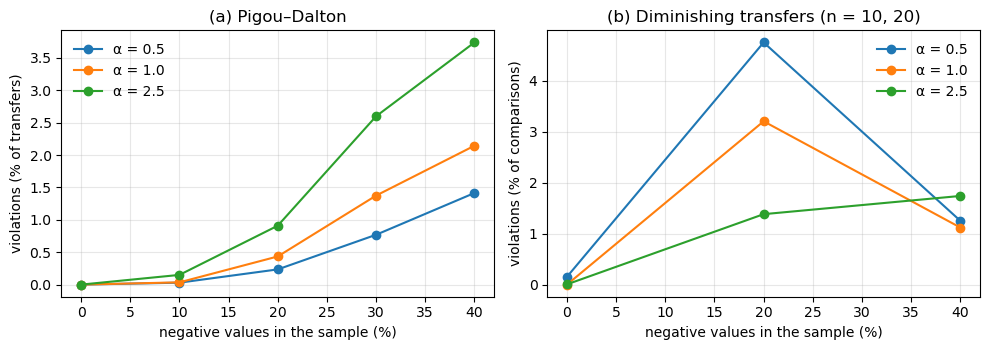

,criterion,alpha,neg_share,n,tests,violations,note
0,formula fidelity,0.5/1/2.5,0/0.2,4-14,2000,0,max deviation 7.1e-15
1,scale invariance,1.0,0.0,4-14,20000,0,max deviation 4.4e-16
2,population invariance,1.0,0.0,4-14,20000,0,max deviation 4.4e-16
3,maximum inequality = (n-1)/n,1.0,0.0,10,1,0,Angular Gini = 0.900000
4,arctangent representation (Proposition 1),1.0,0.0,pairs,20000,0,max deviation 3.3e-16
...,...,...,...,...,...,...,...
122,"stress design, sign class: across zero, recipi...",1.0,2 to n-3 negative values,8-40,961,783,rate 81.48 %
123,"stress design, sign class: across zero, recipi...",1.0,2 to n-3 negative values,8-40,17261,243,rate 1.41 %
124,"stress design, sign class: both negative",1.0,2 to n-3 negative values,8-40,8963,2,rate 0.02 %
125,"stress design, sign class: both non-negative",1.0,2 to n-3 negative values,8-40,32815,234,rate 0.71 %


In [16]:
# ------------------------------------------------------------------
# Summary table and figure
# ------------------------------------------------------------------
summary = pd.DataFrame(results)
summary.to_csv(OUT_DIR / "ag_properties_results.csv", index=False)
print(f"{len(summary)} rows written to {OUT_DIR / 'ag_properties_results.csv'}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)

# Panel a: Pigou-Dalton, violation rate in % per share of negative values
pdd = summary[summary["criterion"] == "Pigou-Dalton"].copy()
pdd["rate"] = 100 * pdd["violations"] / pdd["tests"]
for alpha, g in pdd.groupby("alpha"):
    axes[0].plot(g["neg_share"] * 100, g["rate"], marker="o", label=f"α = {alpha}")
axes[0].set(title="(a) Pigou–Dalton", xlabel="negative values in the sample (%)", ylabel="violations (% of transfers)")

# Panel b: diminishing transfers (marginal), averaged over n = 10 and 20
# (n = 5 is left out: with 40 % negative values the design has hardly any freedom there)
kd = summary[summary["criterion"] == "diminishing transfers (marginal)"].copy()
kd = kd[kd["n"].isin([10, 20])]
for alpha, g in kd.groupby("alpha"):
    a = g.groupby("neg_share")[["violations", "tests"]].sum()
    axes[1].plot(a.index * 100, 100 * a["violations"] / a["tests"], marker="o", label=f"α = {alpha}")
axes[1].set(title="(b) Diminishing transfers (n = 10, 20)", xlabel="negative values in the sample (%)",
            ylabel="violations (% of comparisons)")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(OUT_DIR / "ag_properties_fig_alpha.png", dpi=150)
plt.show()

display(summary.round(3))

### Figure 2 of the manuscript

The three-panel figure of the manuscript (published index, α = 1) is drawn from the summary table above: (a) violations of the Pigou–Dalton principle by share of negative values, (b) violations of the principle of diminishing transfers (marginal form) by share of negative values and sample size, (c) transfers classified by the signs of the two persons involved. It is saved as `output/ag_properties_fig_violations.pdf` (and `.png`).

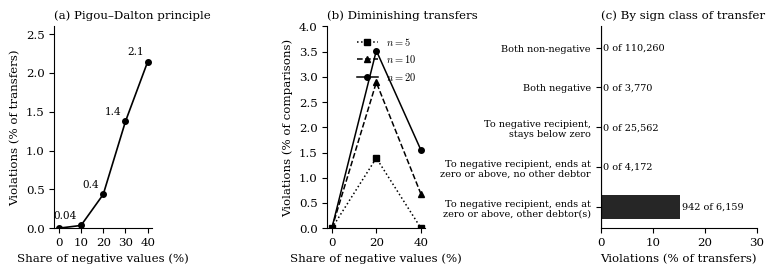

In [17]:
# ------------------------------------------------------------------
# Figure 2 of the manuscript: published index (alpha = 1), three panels
# ------------------------------------------------------------------
def make_fig_violations(d):
    d = d.copy(); d["alpha"] = d["alpha"].astype(str)
    a1 = d[d["alpha"] == "1.0"]
    with plt.rc_context({"font.size": 8.5, "font.family": "serif", "mathtext.fontset": "cm",
                         "axes.spines.top": False, "axes.spines.right": False}):
        fig, ax = plt.subplots(1, 3, figsize=(7.8, 2.8), gridspec_kw={"width_ratios": [1, 1, 1.6]})

        # (a) Pigou-Dalton principle by share of negative values
        p = a1[a1["criterion"] == "Pigou-Dalton"].astype({"neg_share": float}).sort_values("neg_share")
        x = 100 * p["neg_share"].values; y = 100 * p["violations"].values / p["tests"].values
        ax[0].plot(x, y, "o-", color="k", ms=4, lw=1.2)
        for xi, yi in zip(x[1:], y[1:]):
            ax[0].annotate(f"{yi:.2f}" if yi < 0.1 else f"{yi:.1f}", (xi, yi), textcoords="offset points",
                           xytext=(-3, 5), ha="right", fontsize=7.5)
        ax[0].set_xlabel("Share of negative values (%)"); ax[0].set_ylabel("Violations (% of transfers)")
        ax[0].set_title("(a) Pigou–Dalton principle", fontsize=8.5, loc="left"); ax[0].set_ylim(0, 2.6); ax[0].set_xticks([0, 10, 20, 30, 40])

        # (b) diminishing transfers (marginal form) by sample size
        m = a1[a1["criterion"] == "diminishing transfers (marginal)"].astype({"neg_share": float, "n": int})
        for n_, mk, ls in [(5, "s", ":"), (10, "^", "--"), (20, "o", "-")]:
            q = m[m["n"] == n_].sort_values("neg_share")
            ax[1].plot(100 * q["neg_share"], 100 * q["violations"] / q["tests"], marker=mk, ls=ls, color="k", ms=4, lw=1.1, label=f"$n={n_}$")
        ax[1].set_xlabel("Share of negative values (%)"); ax[1].set_ylabel("Violations (% of comparisons)")
        ax[1].set_title("(b) Diminishing transfers", fontsize=8.5, loc="left"); ax[1].set_xticks([0, 20, 40]); ax[1].set_ylim(0, 4)
        ax[1].legend(frameon=False, fontsize=7.5, loc="upper right")

        # (c) transfers classified by the signs of the two persons
        row = lambda s: d[d["criterion"] == s].iloc[0]
        cls = [("Both non-negative", [row("sign class: both non-negative")]),
               ("Both negative", [row("sign class: both negative")]),
               ("To negative recipient,\nstays below zero", [row("sign class, across zero: recipient stays < 0, no other negative person"),
                                                             row("sign class, across zero: recipient stays < 0, other negative person(s)")]),
               ("To negative recipient, ends at\nzero or above, no other debtor", [row("sign class, across zero: recipient ends >= 0, no other negative person")]),
               ("To negative recipient, ends at\nzero or above, other debtor(s)", [row("sign class, across zero: recipient ends >= 0, other negative person(s)")])]
        rates, labels, ns = [], [], []
        for lab, rows_ in cls:
            t = sum(r["tests"] for r in rows_); v = sum(r["violations"] for r in rows_)
            rates.append(100 * v / t); ns.append((v, t)); labels.append(lab)
        yy = np.arange(len(cls))[::-1]
        ax[2].barh(yy, rates, color=["0.75"] * 4 + ["0.15"], height=0.6)
        for yi, r_, (v, t) in zip(yy, rates, ns):
            ax[2].text(r_ + 0.4, yi, f"{v:,} of {t:,}", va="center", fontsize=7)
        ax[2].axvline(0, color="k", lw=0.8)
        ax[2].set_yticks(yy); ax[2].set_yticklabels(labels, fontsize=7); ax[2].set_xlim(0, 30); ax[2].set_xlabel("Violations (% of transfers)")
        ax[2].set_title("(c) By sign class of transfer", fontsize=8.5, loc="left")
        plt.tight_layout(w_pad=1.2)
        plt.savefig(OUT_DIR / "ag_properties_fig_violations.pdf")
        plt.savefig(OUT_DIR / "ag_properties_fig_violations.png", dpi=130)
        plt.show()

make_fig_violations(pd.read_csv(OUT_DIR / "ag_properties_results.csv"))

## Reading the results

- **Non-negative data, α = 1 (the published index):** no violation of the bounds or of the Pigou–Dalton principle was found (Pigou–Dalton is now proved, see "Analytic results"), and in the random designs with n ≤ 20 no violation of the diminishing-transfers principle was found either. That principle is, however, **not valid in general**: it is proved only under a dispersion bound, and a counterexample with n = 1004 exists (Example 1). Scale invariance, population invariance and weak decomposability hold to rounding error.
- **Exponent α ≠ 1:** the diminishing-transfers principle is violated occasionally, even for non-negative data. The exponent is therefore not part of the index.
- **Negative values:** the upper bound (n−1)/n, the Pigou–Dalton principle and the diminishing-transfers principle are all violated. For Pigou–Dalton the violation rate increases with the share of negative values. For the diminishing-transfers principle the rate is positive in every setting with negative values but not monotone in this design (highest at 20 %, lower at 40 %); it depends on where the pairs sit relative to zero, so I would only claim that violations occur. The normalization to [0, 1] is lost as well, and the index explodes when the mean approaches 0. For the paper this means: state the properties for non-negative data and name negative values as a limitation, together with the counterexample above.
- **Numbers in the paper:** Table 1, the examples of Section 4.1 and the counterexample of Table 4 are recalculated in this notebook (rows "reproduced" in the summary table; `violations` = number of published numbers that differ at the printed precision).
- **Gastwirth-type indices:** the Gastwirth index and the pairwise mean of the angular difference alone violate the Pigou–Dalton principle already at moderate dispersion, and the more often the higher the dispersion; the Gini coefficient and the Angular Gini show no violation in the same samples.
- **Angular Lorenz index** (angles of the Lorenz curve, called C in version 1): with sorted Lorenz points it satisfied the Pigou–Dalton principle in every simulated transfer, with and without negative values, and the argument in the section above shows why. It is not invariant to replication of the population, and no decomposition into within- and between-group terms is known. If the values are not sorted before the Lorenz points are formed, the Pigou–Dalton principle is violated often, because the result is then not a Lorenz curve.
- **Sign classes:** in the generator used for the classification, violations of the Pigou–Dalton principle occur only for a non-negative donor and a negative recipient who ends at 0 or above, and only if another negative person exists. This is not a property of the index: adversarial and stress designs produce violations for transfers between two non-negative persons, between two negative persons, and for recipients who stay negative. The conjecture that only transfers across zero fail is therefore refuted (section "The conjecture on transfers across zero"); what can be proved are sufficient conditions for safe transfers (Proposition 7) and a construction of violations for transfers that bring a recipient to zero (Proposition 8).
- The cells of the table with `n = 5` and 40 % negative values leave very little freedom in the Kolm design; read the zero there with care.
- Apart from the analytic section, these are simulation results. Simulations with n ≤ 20 did not detect the failure of the diminishing-transfers principle in large populations; random designs should be complemented by adversarial configurations (many persons concentrated far above the pairs).